# 1. Data Cleaning & Processing

In [160]:
# Import the packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [161]:
# Set the group colour scheme and display order used in all charts
COLORS = {"CCR": "#6b2c7e", "RCR": "#c24e22", "OCR": "#23786f"}
REGIONS = ["CCR", "RCR", "OCR"]
SALES = ["New Sale", "Sub Sale", "Resale"]

In [162]:
# Set the link to the raw data files in our GitHub repo
URL = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/"

In [163]:
# Load the transaction data for each period
df23 = pd.read_csv(URL + "properties23.csv")     # Aug 2020 to Dec 2023
df24 = pd.read_csv(URL + "properties2024.csv")   # 2024
df25 = pd.read_csv(URL + "properties2025.csv")   # 2025

In [164]:
# Check the number of rows and columns in each file -> should show as (74571, 12) (19893, 12) (24151, 12)
print(df23.shape, df24.shape, df25.shape)

(74571, 12) (19893, 12) (24151, 12)


In [165]:
# Combine all three periods into one table -> should show as (118615, 12)
df = pd.concat([df23, df24, df25], ignore_index=True)   # columns are matched by name
print(df.shape)

(118615, 12)


In [166]:
# Remove extra spaces at the start or end of text columns
for col in ["project", "street", "type", "segment", "tenure", "sale", "level"]:
    df[col] = df[col].str.strip()   # e.g. " Resale" becomes "Resale"

In [167]:
# Fix tenure labels so each type has only one spelling
df["tenure"] = df["tenure"].replace({"freenhold": "freehold",   # typo in 2025 file
                                     "others": "other"})        # 2024 file uses "others"

# Remove "other" tenure
df = df[df["tenure"] != "other"].copy()   # .copy() makes it a separate table, not a view
print(df["tenure"].value_counts())

tenure
99 years              81947
freehold              32797
less than 99 years       17
Name: count, dtype: int64


In [168]:
# Convert the date text (e.g. "Dec-25") into a real date
df["date"] = pd.to_datetime(df["date"], format="%b-%y")   # %b = short month, %y = 2-digit year

In [169]:
# Add the year and quarter of each transaction
df["year"] = df["date"].dt.year                  # e.g. 2025
df["quarter"] = df["date"].dt.to_period("Q")     # e.g. 2025Q4
print(df[["date", "year", "quarter"]].head())

        date  year quarter
0 2023-12-01  2023  2023Q4
1 2023-12-01  2023  2023Q4
2 2023-12-01  2023  2023Q4
3 2023-12-01  2023  2023Q4
4 2023-12-01  2023  2023Q4


In [170]:
# Calculate price per square foot (PSF) for each transaction
df["psf"] = df["price"] / df["area"]   # S$ per sq ft
print(df["psf"].describe().round(0))

count    114761.0
mean       1886.0
std         617.0
min         274.0
25%        1417.0
50%        1806.0
75%        2315.0
max        6593.0
Name: psf, dtype: float64


In [171]:
# Check for blank cells and exact duplicate rows
print(df.isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

project         0
street          0
type            0
district        0
segment         0
tenure          0
commence    32330
sale            0
price           0
area            0
level           0
date            0
year            0
quarter         0
psf             0
dtype: int64
Exact duplicate rows: 13469


#2. Affordability

In [172]:
# Keep only 2025 transactions for the affordability analysis
aff = df[df["year"] == 2025]
print(aff.shape)

(23294, 15)


In [173]:
# Set up the shared chart style for all three affordability charts
import numpy as np
from matplotlib.colors import to_rgb

def lighten(colour, amount):                             # mix a colour with white (0 = full colour, 1 = white)
    rgb = np.array(to_rgb(colour))
    return tuple(rgb + (1 - rgb) * amount)

LIGHT = {"New Sale": 0, "Sub Sale": 0.4, "Resale": 0.55}           # New darkest, Resale lightest
SHORT = {"New Sale": "New", "Sub Sale": "Sub", "Resale": "Resale"}  # short labels on the chart
Y = {"CCR": 2, "RCR": 1, "OCR": 0}                                  # row position of each region (CCR on top)

In [174]:
# Create a dumbbell chart function (used for both PSF and total price)
def dumbbell(table, title, xlabel, fmt):
    fig, ax = plt.subplots(figsize=(8, 4.6))

    # One row per region: a light line from lowest to highest value, plus one dot per sale type
    for r in REGIONS:
        ax.plot([table.loc[r].min(), table.loc[r].max()], [Y[r], Y[r]], color=lighten(COLORS[r], 0.8), linewidth=5, zorder=1)
        for s in SALES:
            v = table.loc[r, s]
            border = "none" if s == "Resale" else COLORS[r]                  # Resale dots have no border
            ax.scatter(v, Y[r], s=190, color=lighten(COLORS[r], LIGHT[s]), edgecolor=border, linewidth=1.5, zorder=3)
            offset = -0.32 if s == "Sub Sale" else 0.3                       # Sub label below the dot, others above
            ax.text(v, Y[r] + offset, f"{SHORT[s]} {fmt(v)}", ha="center", va="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1))

    # Grey legend for sale type, placed in the empty bottom-right corner
    for s in SALES:
        border = "none" if s == "Resale" else "#555555"
        ax.scatter([], [], s=90, color=lighten("#555555", LIGHT[s]), edgecolor=border, linewidth=1.5, label=SHORT[s])
    ax.legend(frameon=False, loc="lower right", fontsize=9, title="Sale type", title_fontsize=9, alignment="left")

    # Region names on the left, in region colours
    ax.set_yticks([Y[r] for r in REGIONS])
    ax.set_yticklabels(REGIONS, fontsize=12, fontweight="bold")
    for tick, r in zip(ax.get_yticklabels(), REGIONS):
        tick.set_color(COLORS[r])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, 2.55)

    # Title, axis label, and remove extra borders
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)

    plt.tight_layout()
    plt.show()

In [175]:
# Calculate median PSF for each region and sale type
psf = aff.pivot_table(index="segment", columns="sale", values="psf", aggfunc="median")   # rows = region, columns = sale type
psf = psf.loc[REGIONS, SALES]                                                             # put rows and columns in our set order
print(psf.round(0))

sale     New Sale  Sub Sale  Resale
segment                            
CCR        3031.0    2955.0  2177.0
RCR        2789.0    2197.0  1928.0
OCR        2255.0    1907.0  1532.0


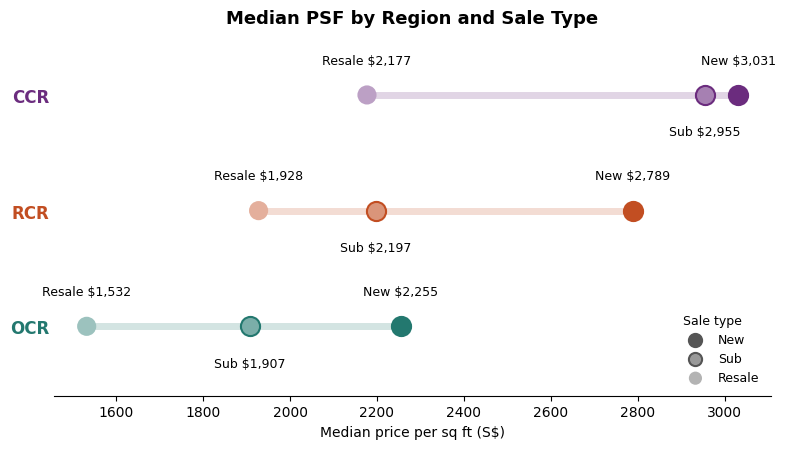

In [176]:
# Plot the median PSF dumbbell chart
dumbbell(psf, "Median PSF by Region and Sale Type", "Median price per sq ft (S$)", lambda v: f"${v:,.0f}")   # label format: $3,031

In [177]:
# Calculate median total price for each region and sale type, in S$ million
price = aff.pivot_table(index="segment", columns="sale", values="price", aggfunc="median")   # rows = region, columns = sale type
price = price.loc[REGIONS, SALES] / 1e6                                                     # set order, convert to millions
print(price.round(2))

sale     New Sale  Sub Sale  Resale
segment                            
CCR          2.18      2.05    2.65
RCR          2.25      1.80    1.79
OCR          1.87      1.55    1.43


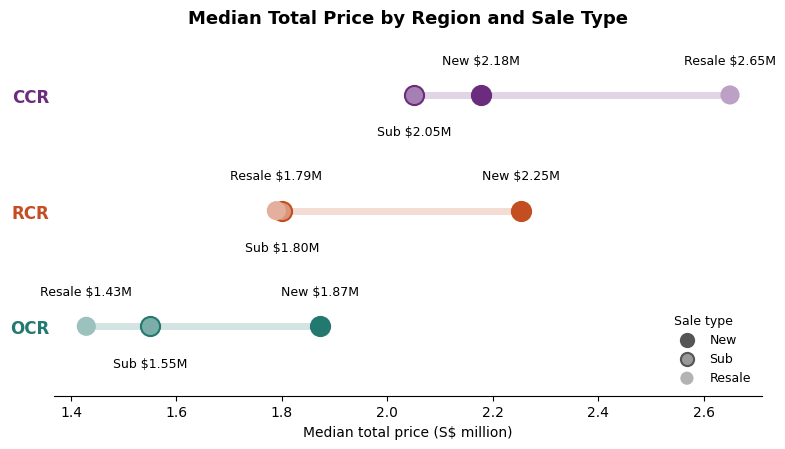

In [178]:
# Plot the median total price dumbbell chart
dumbbell(price, "Median Total Price by Region and Sale Type", "Median total price (S$ million)", lambda v: f"${v:.2f}M")   # label format: $2.18M

In [179]:
# Calculate median unit size for each region and sale type
size = aff.pivot_table(index="segment", columns="sale", values="area", aggfunc="median")   # rows = region, columns = sale type
size = size.loc[REGIONS, SALES]                                                            # put rows and columns in our set order
print(size.round(0))

sale     New Sale  Sub Sale  Resale
segment                            
CCR         732.0     710.0  1206.0
RCR         823.0     764.0   958.0
OCR         807.0     764.0   980.0


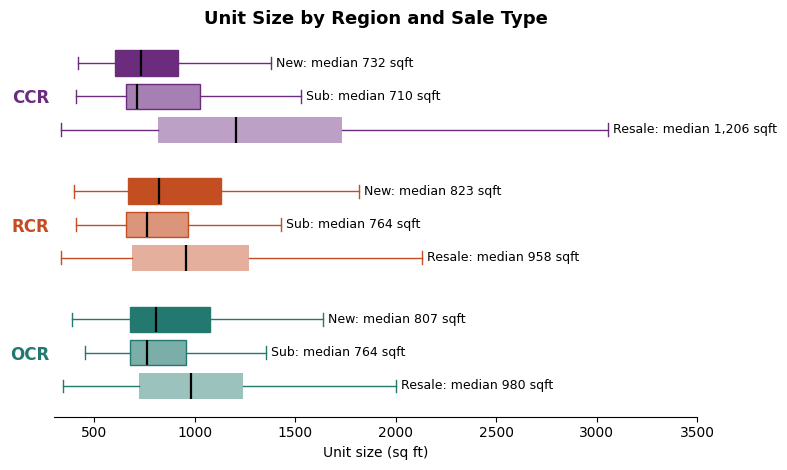

In [180]:
# Plot unit size as a box plot for each region and sale type
fig, ax = plt.subplots(figsize=(8, 4.8))

for r in REGIONS:
    for j, s in enumerate(SALES):
        units = aff[(aff["segment"] == r) & (aff["sale"] == s)]["area"]   # unit sizes for this region and sale type
        ypos = Y[r] - (j - 1) * 0.26                                       # stack New, Sub, Resale within each region row

        # Draw the box (standard 1.5 x IQR whiskers, outliers hidden)
        box = ax.boxplot(units, positions=[ypos], orientation="horizontal", widths=0.2, whis=1.5, showfliers=False, patch_artist=True,
                         medianprops=dict(color="black", linewidth=1.6), whiskerprops=dict(color=COLORS[r]), capprops=dict(color=COLORS[r]))
        box["boxes"][0].set(facecolor=lighten(COLORS[r], LIGHT[s]), edgecolor="none" if s == "Resale" else COLORS[r])

        # Write the median at the end of the right whisker
        q1, q3 = units.quantile(0.25), units.quantile(0.75)
        whisker_end = units[units <= q3 + 1.5 * (q3 - q1)].max()
        ax.text(whisker_end + 25, ypos, f"{SHORT[s]}: median {units.median():,.0f} sqft", va="center", fontsize=9)

# Region names on the left, in region colours
ax.set_yticks([Y[r] for r in REGIONS])
ax.set_yticklabels(REGIONS, fontsize=12, fontweight="bold")
for tick, r in zip(ax.get_yticklabels(), REGIONS):
    tick.set_color(COLORS[r])
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.5, 2.5)
ax.set_xlim(300, 3500)

# Title, axis label, and remove extra borders
ax.set_title("Unit Size by Region and Sale Type", fontsize=13, fontweight="bold")
ax.set_xlabel("Unit size (sq ft)")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

#3. Accessibility

  ## MRT Accessibility - Data

3.1 Proximity of 99 Years and Freehold Properties to the Nearest MRT Station Exits



Property dataset loaded successfully!
Total property records: 24,151
MRT exit dataset loaded successfully!
Total MRT exit records: 613
Planning area dataset loaded successfully!

MRT exit distribution by market segment:
segment
CCR    134
RCR    171
OCR    219
Name: count, dtype: int64


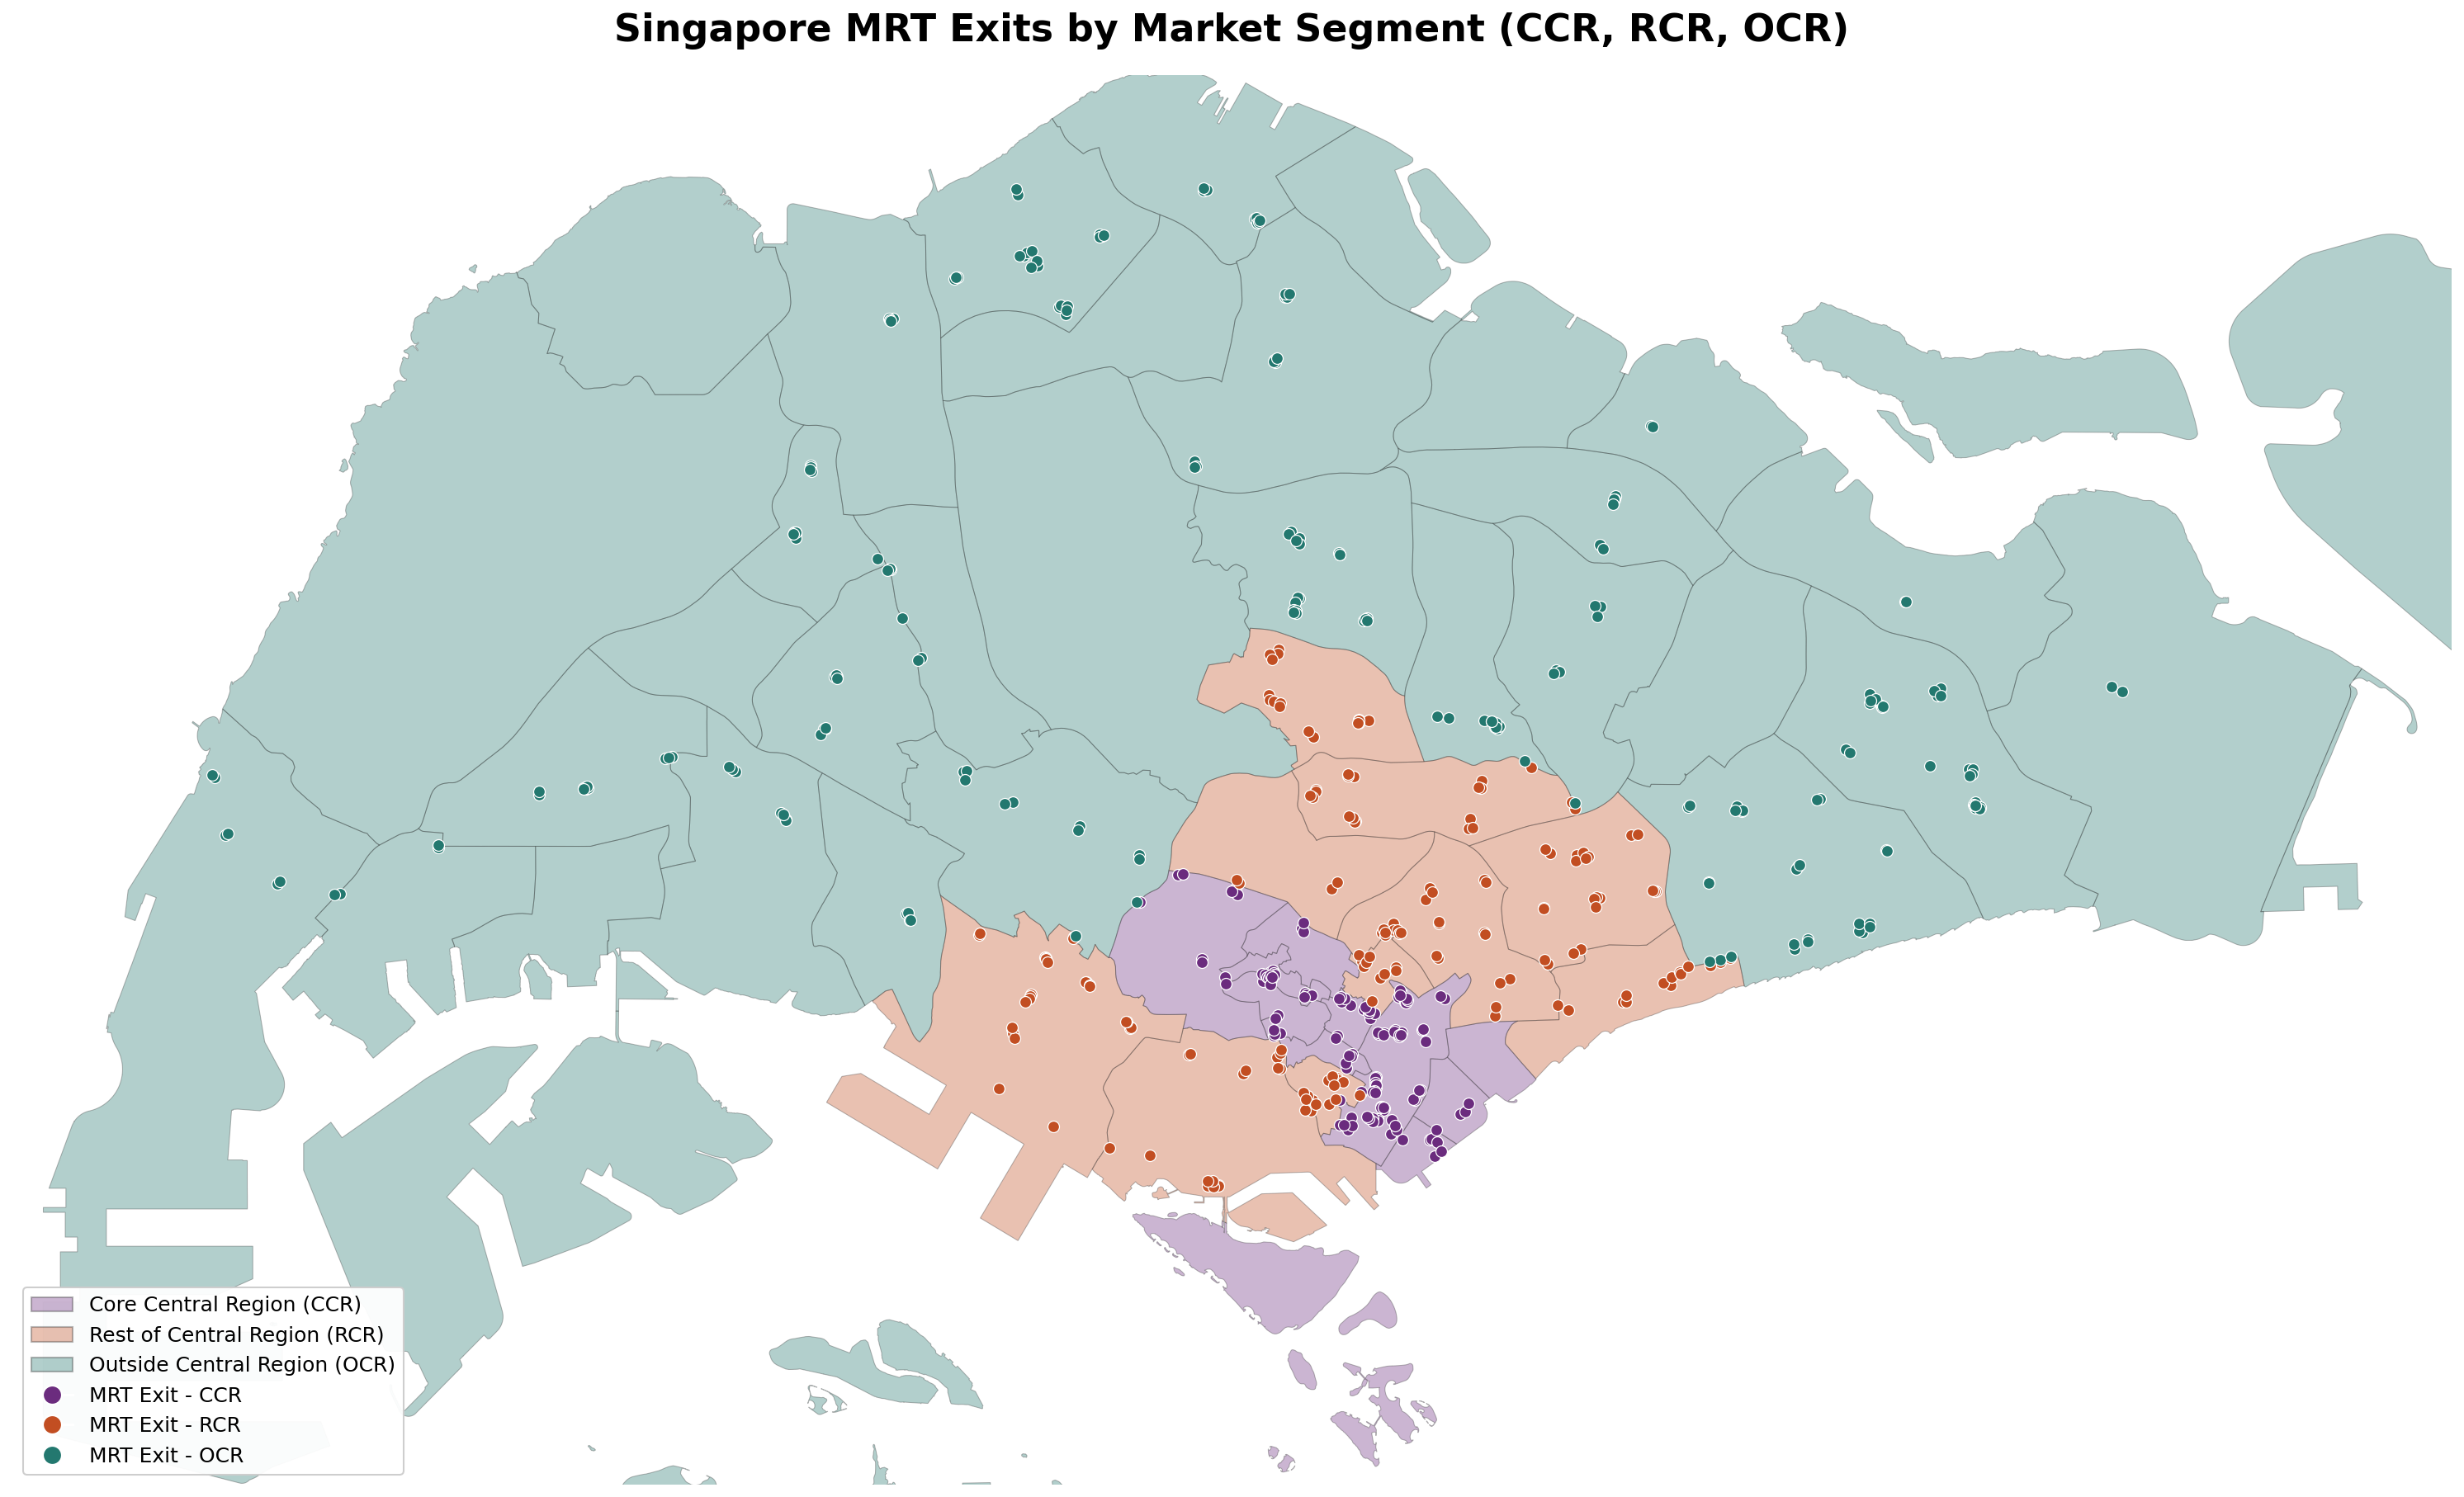

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Your Singapore MRT geomap has been generated successfully!


In [181]:

# ============================================================
# DAO2702: SINGAPORE MRT EXITS BY MARKET SEGMENT
# Data loaded directly from GitHub
# ============================================================

!pip -q install geopandas matplotlib pandas requests

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from google.colab import files
from IPython.display import display, Image
import geopandas as gpd
import pandas as pd

# ============================================================
# 1. LOAD DATA DIRECTLY FROM GITHUB
# ============================================================

GITHUB_BASE = (
    "https://raw.githubusercontent.com/"
    "hawflakess/DAO2702-Group-Assignment/main/"
)

property_url = GITHUB_BASE + "properties2025_cleaned.csv"

mrt_url = (
    GITHUB_BASE +
    "LTAMRTStationExitGEOJSON.geojson"
)

planning_url = (
    GITHUB_BASE +
    "MasterPlan2019PlanningAreaBoundaryNoSea.geojson"
)

# Load property transaction dataset
df = pd.read_csv(property_url)
df.columns = df.columns.str.strip()

print("Property dataset loaded successfully!")
print(f"Total property records: {len(df):,}")

# Load MRT exit GeoJSON
mrt_exits_gdf = gpd.read_file(mrt_url)

print("MRT exit dataset loaded successfully!")
print(f"Total MRT exit records: {len(mrt_exits_gdf):,}")

# Load planning area GeoJSON
planning_area_gdf = gpd.read_file(planning_url)

print("Planning area dataset loaded successfully!")

# ============================================================
# 2. ENSURE MATCHING COORDINATE SYSTEMS
# ============================================================

# Convert both datasets to WGS84
mrt_exits_gdf = mrt_exits_gdf.to_crs(epsg=4326)

planning_area_gdf = planning_area_gdf.to_crs(epsg=4326)

# Keep valid point geometries
mrt_exits_gdf = mrt_exits_gdf[
    mrt_exits_gdf.geometry.notna()
    & mrt_exits_gdf.geom_type.eq("Point")
].copy()

# Keep MRT exits only, excluding LRT
mrt_exits_gdf = mrt_exits_gdf[
    mrt_exits_gdf["STATION_NA"]
    .astype(str)
    .str.contains(r"\bMRT\b", case=False, na=False)
].copy()

# ============================================================
# 3. DEFINE CCR, RCR AND OCR
# ============================================================

ccr_areas = [
    'DOWNTOWN CORE',
    'SINGAPORE RIVER',
    'MUSEUM',
    'NEWTON',
    'ORCHARD',
    'RIVER VALLEY',
    'TANGLIN',
    'MARINA EAST',
    'MARINA SOUTH',
    'STRAITS VIEW',
    'SOUTHERN ISLANDS',
    'SENTOSA'
]

rcr_areas = [
    'QUEENSTOWN',
    'ALEXANDRA',
    'BUKIT MERAH',
    'TELOK BLANGAH',
    'DEPOT ROAD',
    'OUTRAM',
    'ROCHOR',
    'KALLANG',
    'GEYLANG',
    'TOA PAYOH',
    'NOVENA',
    'MARINE PARADE',
    'BISHAN'
]

def get_segment(row):

    name = str(row['PLN_AREA_N']).upper().strip()

    if name in ccr_areas:
        return 'CCR'

    elif name in rcr_areas:
        return 'RCR'

    else:
        return 'OCR'

planning_area_gdf['segment'] = (
    planning_area_gdf.apply(get_segment, axis=1)
)

# ============================================================
# 4. APPLY YOUR REQUESTED COLOUR SCHEME
# ============================================================

segment_colors = {
    'CCR': '#6b2c7e',
    'RCR': '#c24e22',
    'OCR': '#23786f'
}

planning_area_gdf['color'] = (
    planning_area_gdf['segment'].map(segment_colors)
)

# ============================================================
# 5. SPATIAL JOIN MRT EXITS WITH PLANNING AREAS
# ============================================================

# Keep only columns needed for spatial join
planning_segments = planning_area_gdf[
    ['PLN_AREA_N', 'segment', 'geometry']
].copy()

mrt_with_areas = gpd.sjoin(
    mrt_exits_gdf,
    planning_segments,
    how='inner',
    predicate='within'
)

print("\nMRT exit distribution by market segment:")

print(
    mrt_with_areas['segment']
    .value_counts()
    .reindex(['CCR', 'RCR', 'OCR'], fill_value=0)
)

# ============================================================
# 6. CREATE CLEAN SINGAPORE GEOMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(20, 14),
    dpi=150
)

# Plot planning area boundaries
planning_area_gdf.plot(
    ax=ax,
    color=planning_area_gdf['color'],
    edgecolor='#333333',
    linewidth=0.5,
    alpha=0.35,
    zorder=1
)

# Plot MRT exits
for segment, color in segment_colors.items():

    mrt_subset = mrt_with_areas[
        mrt_with_areas['segment'] == segment
    ]

    if len(mrt_subset) > 0:

        ax.scatter(
            mrt_subset.geometry.x,
            mrt_subset.geometry.y,
            color=color,
            edgecolors='white',
            linewidths=0.6,
            s=45,
            zorder=3
        )

# ============================================================
# 7. TITLE
# ============================================================

ax.set_title(
    'Singapore MRT Exits by Market Segment (CCR, RCR, OCR)',
    fontsize=22,
    fontweight='bold',
    pad=20
)

# ============================================================
# 8. LEGEND AT BOTTOM LEFT
# ============================================================

legend_elements = [

    Patch(
        facecolor=segment_colors['CCR'],
        edgecolor='#333333',
        alpha=0.35,
        label='Core Central Region (CCR)'
    ),

    Patch(
        facecolor=segment_colors['RCR'],
        edgecolor='#333333',
        alpha=0.35,
        label='Rest of Central Region (RCR)'
    ),

    Patch(
        facecolor=segment_colors['OCR'],
        edgecolor='#333333',
        alpha=0.35,
        label='Outside Central Region (OCR)'
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=segment_colors['CCR'],
        markeredgecolor='white',
        markersize=11,
        label='MRT Exit - CCR'
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=segment_colors['RCR'],
        markeredgecolor='white',
        markersize=11,
        label='MRT Exit - RCR'
    ),

    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=segment_colors['OCR'],
        markeredgecolor='white',
        markersize=11,
        label='MRT Exit - OCR'
    )
]

ax.legend(
    handles=legend_elements,
    loc='lower left',
    fontsize=12,
    frameon=True,
    facecolor='white',
    framealpha=0.95
)

# ============================================================
# 9. SET SINGAPORE MAP VIEW
# ============================================================

ax.set_xlim(103.6, 104.05)
ax.set_ylim(1.21, 1.47)

ax.axis('off')

plt.tight_layout()

# ============================================================
# 10. SAVE HIGH-RESOLUTION IMAGE
# ============================================================

output_path = (
    '/content/singapore_mrt_clean_poster_map.png'
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

# Display map directly in Google Colab
plt.show()

# ============================================================
# 11. DOWNLOAD IMAGE
# ============================================================

files.download(output_path)

print(
    "\nYour Singapore MRT geomap has been "
    "generated successfully!"
)


In [182]:
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

# 1. Load uniquely geocoded property projects from GitHub
base_url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/Amenities_Accessibility/"
projects_df = pd.read_csv(base_url + "residential_projects_geocoded.csv")

# Drop rows with missing latitude or longitude
projects_df = projects_df.dropna(subset=['lat', 'lon']).copy()

# Convert properties to a GeoDataFrame and project to Singapore's metre-based SVY21 coordinate system
projects_gdf = gpd.GeoDataFrame(
    projects_df,
    geometry=gpd.points_from_xy(projects_df['lon'], projects_df['lat']),
    crs="EPSG:4326"
).to_crs(epsg=3414)

# 2. Load MRT exits and project to the same system
mrt_url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/LTAMRTStationExitGEOJSON.geojson"
mrt_gdf = gpd.read_file(mrt_url).to_crs(epsg=4326)

# Drop empty geometries and filter out LRT exits
mrt_gdf = mrt_gdf[mrt_gdf.geometry.notna() & ~mrt_gdf.geometry.is_empty & mrt_gdf.geom_type.eq("Point")].copy()
mrt_gdf = mrt_gdf[mrt_gdf["STATION_NA"].astype(str).str.contains(r"\bMRT\b", case=False, na=False)].copy()
mrt_projected = mrt_gdf.to_crs(epsg=3414)

# 3. Calculate the distance to the nearest MRT exit using KDTree
mrt_coords = np.column_stack([mrt_projected.geometry.x, mrt_projected.geometry.y])
project_coords = np.column_stack([projects_gdf.geometry.x, projects_gdf.geometry.y])

mrt_tree = cKDTree(mrt_coords)
distances, _ = mrt_tree.query(project_coords, k=1)
projects_gdf['distance_to_mrt_m'] = distances

# 4. Group by market segment and show the average distance
summary_stats = projects_gdf.groupby('segment')['distance_to_mrt_m'].agg(['mean', 'count'])
summary_stats.columns = ['Average Distance to MRT (m)', 'Project Count']
summary_stats = summary_stats.reindex(['CCR', 'RCR', 'OCR'])

print("=== Average Distance from Property Projects to the Nearest MRT Exit ===")
display(summary_stats.round(1))

=== Average Distance from Property Projects to the Nearest MRT Exit ===


,Average Distance to MRT (m),Project Count
segment,,
CCR,461.6,531
RCR,469.6,661
OCR,676.3,600


3.1.1 Interactive GeoMap

In [183]:
from pathlib import Path
from html import escape
from IPython.display import HTML, display

# Set this to True to download index.html after displaying it.
DOWNLOAD_HTML = False

# Keep the r before the triple quotes. It preserves JavaScript
# backslashes inside this Python string.
WEBSITE_HTML = r"""<!DOCTYPE html>

<html lang="en">
<head>
<meta charset="utf-8"/><meta content="width=device-width,initial-scale=1" name="viewport"/>
<title>Singapore Property &amp; MRT Explorer | DAO2702</title>
<link href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css" rel="stylesheet"/>
<style>
:root{--ink:#182638;--muted:#607286;--line:#e3e9ef;--paper:#f6f8fb;--cyan:#00cddd;--pink:#f22c84}*{box-sizing:border-box}body{margin:0;font-family:Inter,system-ui,-apple-system,Segoe UI,Arial,sans-serif;color:var(--ink);background:var(--paper)}header{display:flex;align-items:center;justify-content:space-between;padding:18px 24px;background:#fff;border-bottom:1px solid var(--line);gap:12px}h1{font-size:21px;letter-spacing:-.6px;margin:0}header p{margin:4px 0 0;color:var(--muted);font-size:12px}.tag{font-size:11px;color:#277867;background:#e7f6f1;padding:7px 10px;border-radius:999px;white-space:nowrap}.layout{display:grid;grid-template-columns:290px minmax(0,1fr);height:calc(100vh - 85px);min-height:620px}.sidebar{background:white;border-right:1px solid var(--line);padding:21px 19px;overflow-y:auto}.heading{font-size:11px;letter-spacing:1.5px;font-weight:800;color:#8493a3;text-transform:uppercase;margin:21px 0 12px}.heading:first-child{margin-top:0}.legend{display:flex;align-items:center;gap:9px;margin:11px 0;font-size:13px}.dot{width:12px;height:12px;border-radius:50%;border:1px solid #445;flex:none}.swatch{width:13px;height:13px;border-radius:3px;flex:none}.filter{display:flex;gap:8px;align-items:center;font-size:13px;margin:12px 0;cursor:pointer}.filter input{accent-color:#182638}select,input[type=search]{padding:11px 12px;border:1px solid var(--line);border-radius:8px;background:#fff;color:var(--ink);width:100%;font:inherit;font-size:13px}button{cursor:pointer;background:#19283a;color:white;padding:11px;border:none;border-radius:8px;font-weight:700;width:100%}.stats{display:grid;grid-template-columns:1fr 1fr;gap:9px}.stat{padding:12px 10px;border-radius:10px;background:#f5f7fa}.stat b{font-size:22px;display:block}.stat span{font-size:11px;color:var(--muted)}.notice{background:#fff8e9;border:1px solid #f3e0b7;border-radius:9px;padding:12px;color:#71521f;font-size:12px;line-height:1.5;margin-top:20px}.small{font-size:11px;color:var(--muted);line-height:1.6}.map-area{position:relative;min-height:520px}#map{width:100%;height:100%;background:#f7f9fb}.floating{position:absolute;bottom:20px;left:20px;z-index:600;background:rgba(255,255,255,.97);padding:12px 15px;border-radius:9px;box-shadow:0 4px 18px #2333;font-size:12px;max-width:320px}.popup{font-family:inherit;line-height:1.7;min-width:210px}.popup strong{font-size:15px}.popup .sub{font-size:11px;color:#718296;margin:0 0 8px}.walk-panel{margin-top:10px;border-top:1px solid #dde5ec;padding-top:9px}.walk-panel button{font-size:12px;padding:8px;margin-top:5px}.walk-result{font-size:12px;line-height:1.5;margin-top:6px}.walk-panel .hint{color:#66798c;font-size:11px;line-height:1.4}.popup .note{font-size:11px;color:#92743f;margin-top:9px;border-top:1px solid #ddd;padding-top:7px}.mrt-icon{background:transparent;border:0}.mrt-badge{width:22px;height:22px;display:flex;align-items:center;justify-content:center;border-radius:6px;background:#191f29;border:1.5px solid #fff;box-shadow:0 1px 5px #0006}.mrt-badge svg{height:16px;width:16px;display:block}.leaflet-popup-content-wrapper{border-radius:12px}.status{color:#486d81}.error{color:#ac2943}.searchrow{margin-top:12px}.search-actions{display:flex;gap:7px;margin-top:7px}.search-actions button{width:auto;flex:1}.search-status{font-size:11px;color:#607286;margin-top:6px;line-height:1.4}.search-pin{background:transparent;border:0}.key{font-size:11px;color:#607286;margin-top:8px}@media(max-width:780px){header{padding:14px 16px}h1{font-size:17px}.tag{display:none}.layout{display:flex;flex-direction:column;height:auto}.sidebar{padding:14px 16px;max-height:none}.heading{margin:13px 0 7px}.sidebar .filters{display:grid;grid-template-columns:1fr 1fr;gap:0 12px}.sidebar .filters .heading{grid-column:1/-1}.map-area{height:66vh;min-height:460px}.floating{left:10px;bottom:10px;max-width:250px}.stats{grid-template-columns:1fr 1fr}}

.place-matches{display:grid;gap:6px;margin-top:8px;max-height:220px;overflow-y:auto}
.place-match{background:#f5f7fa;color:#182638;text-align:left;font-size:12px;font-weight:500;border:1px solid #e3e9ef;line-height:1.4}
.place-match:hover,.place-match:focus{background:#e8eff6;outline:2px solid #b6c8d9}
.place-match small{display:block;color:#607286;margin-top:3px}
button:disabled{opacity:.6;cursor:wait}
.leaflet-control-attribution{max-width:calc(100vw - 40px);white-space:normal;font-size:10px}

/* Click-to-walk controls keep coordinate fields out of the interface. */
[hidden]{display:none!important}
.walking-card{border:1px solid #dbe6f2;border-radius:12px;padding:12px;background:#f8fbff}
.walking-card .filter{margin-top:0;font-size:12px}.walk-result-main{margin:14px 0;line-height:1.5;font-size:12px;overflow-wrap:anywhere}
.walk-copy{font-size:12px;line-height:1.5;color:#536b80;margin:8px 0}
.secondary{background:#edf2f7;color:#233a50;border:1px solid #d8e2ec;font-size:12px;margin-top:7px}
#pickProperty{background:#1267d5;line-height:1.4}#pickProperty[aria-pressed=true]{background:#24446c}
.route-eyebrow{display:block;color:#60778c;font-size:10px;letter-spacing:1px;text-transform:uppercase;font-weight:750;margin-bottom:5px}
.route-station{font-size:18px;line-height:1.3;margin:0 0 7px;overflow-wrap:anywhere}.exit-label{display:inline-block;border-radius:5px;background:#e1ecfc;color:#164e94;padding:3px 8px;font-size:12px;font-weight:750}
.route-metrics{display:grid;grid-template-columns:1fr 1fr;gap:8px;margin:13px 0}.route-metrics>div{background:white;border:1px solid #dbe6f2;padding:10px 6px;border-radius:8px}.route-metrics b{display:block;font-size:20px;color:#155db5;line-height:1.3}.route-metrics span{display:block;color:#60778c;font-size:10px;margin-top:4px}
.route-link{display:inline-block;font-size:12px;font-weight:600;line-height:1.5;color:#1256a3;margin:3px 0}.route-details{font-size:11px;color:#536b80;line-height:1.55;margin-top:12px}.route-details summary,.service-details summary{cursor:pointer;font-size:11px;font-weight:650}.service-details{margin-top:10px;color:#607286}
progress{width:100%;height:8px;margin:8px 0;accent-color:#1267d5}
.floating{max-width:365px;width:calc(100% - 40px);max-height:45%;overflow-y:auto;bottom:28px;line-height:1.5}.map-station{display:block;font-size:15px;line-height:1.3}.map-metrics{font-weight:800;color:#155db5;font-size:21px;margin-top:6px}.map-metrics span{font-size:12px;font-weight:500}.route-actions{display:flex;gap:12px;align-items:center}.route-actions button{width:auto;flex:1;font-size:11px;padding:8px}.route-actions a{font-size:12px;color:#1256a3}
.pick-banner{position:absolute;left:60px;right:15px;top:12px;z-index:650;background:#192d49;color:white;border:2px solid white;border-radius:10px;padding:11px 13px;box-shadow:0 2px 12px #0003;display:flex;gap:12px;align-items:center;font-size:13px;line-height:1.5}.pick-banner span{flex:1}.pick-banner button{width:auto;margin:0;flex:none}
.picking-property,.picking-property .leaflet-interactive{cursor:crosshair!important}.picking-property .leaflet-marker-pane *,.picking-property .leaflet-shadow-pane *,.picking-property .leaflet-overlay-pane{pointer-events:none!important}
.home-map-icon{background:transparent;border:0}.home-map-icon svg{display:block;filter:drop-shadow(0 2px 3px #0005)}
button:focus-visible,a:focus-visible,summary:focus-visible{outline:3px solid #4489ed;outline-offset:2px}
@media(max-width:780px){.floating{left:10px;bottom:30px;width:calc(100% - 20px);max-width:340px;max-height:41%;padding:10px 12px}.pick-banner{left:52px;right:8px;top:10px;font-size:11px;padding:8px;gap:6px}.map-metrics{font-size:19px}.route-metrics b{font-size:22px}.walking-card{margin-top:8px}}
</style></head><body>
<header><div><h1>Singapore Property &amp; MRT Explorer</h1><p>DAO2702 · Property transactions, tenure and MRT exit locations</p></div><div class="tag">Interactive map · No API key</div></header>
<div class="layout"><aside class="sidebar"><div class="heading">Overview</div><div class="stats"><div class="stat"><b id="propertyCount">–</b><span>Property markers</span></div><div class="stat"><b id="mrtCount">–</b><span>MRT / LRT exits</span></div></div><div class="heading">Property tenure</div><div class="filters"><label class="filter"><input checked="" id="lease" type="checkbox"/><span class="dot" style="background:var(--cyan)"></span> 99-year leasehold</label><label class="filter"><input checked="" id="freehold" type="checkbox"/><span class="dot" style="background:var(--pink)"></span> Freehold</label><label class="filter"><input checked="" id="mrt" type="checkbox"/> <span class="mrt-badge" style="width:19px;height:19px;flex:none;border-radius:5px"><svg aria-hidden="true" fill="none" stroke="white" stroke-linecap="round" stroke-linejoin="round" stroke-width="2" viewbox="0 0 24 24"><rect height="15" rx="3" width="14" x="5" y="3"></rect><path d="M5 10h14M8 21l2-3m6 0 2 3"></path><circle cx="9" cy="14" fill="white" r="1" stroke="none"></circle><circle cx="15" cy="14" fill="white" r="1" stroke="none"></circle></svg></span> MRT station exits</label><label class="filter"><input checked="" id="areas" type="checkbox"/> Planning area boundaries</label></div><div class="heading">Market segments</div><div class="legend"><span class="swatch" style="background:#6b2c7e"></span> Core Central Region (CCR)</div><div class="legend"><span class="swatch" style="background:#c24e22"></span> Rest of Central Region (RCR)</div><div class="legend"><span class="swatch" style="background:#23786f"></span> Outside Central Region (OCR)</div><div class="heading">Filter properties</div><select id="segment"><option value="ALL">All market segments</option><option>CCR</option><option>RCR</option><option>OCR</option></select><div class="searchrow"><input id="search" placeholder="Search property name or street" type="search"/></div><div class="search-actions"><button id="zoomProperty" type="button">Zoom to matching property</button></div><div class="heading">Find a location</div><input aria-label="Search a location in Singapore" id="placeSearch" placeholder="MRT station, property address or landmark" type="search"/><div class="search-actions"><button id="findPlace" type="button">Search and zoom</button><button id="clearPlace" type="button">Clear pin</button></div><div aria-live="polite" class="search-status" id="placeStatus">Search your address to zoom in, then use "Click my property" to select the building entrance. No coordinates to type.</div><div aria-label="Matching locations" class="place-matches" id="placeMatches"></div><div class="key">Shows up to 1,000 records per tenure, matching the original Colab sample.</div><div class="heading">Walk to the nearest MRT exit</div>
<section aria-label="Choose your property and find a walking route" class="walking-card">
<label class="filter"><input id="roadmap" type="checkbox"/> Show streets (OneMap, no key)</label>
<button aria-pressed="false" disabled="" id="pickProperty" type="button">Click my property</button>
<div aria-busy="false" aria-live="polite" class="walk-result-main" id="walkResult" role="status"></div>
<button class="secondary" id="clearWalk" type="button">Clear route &amp; restore property dots</button>
</section>
<p class="small">Only the building you select is used for walking calculations. The original coloured dots are illustrative.</p>
<details class="service-details"><summary>Services &amp; privacy</summary>
<p class="small">OneMap street background; local MRT data / Photon address search; Valhalla pedestrian routing. No account or API key is entered. Public services can be unavailable or rate-limited. Your selected map point and candidate exits are sent to the routing service only when you request a route. Route caching stays in this browser tab.</p>
<p class="small"><a href="https://fossgis.de/arbeitsgruppen/osm-server/nutzungsbedingungen/" rel="noopener noreferrer" target="_blank">Routing service terms</a> · <a href="https://valhalla.github.io/valhalla/api/route/api-reference/" rel="noopener noreferrer" target="_blank">Routing documentation</a></p></details>
<div class="heading">Map tools</div><button id="reset">Reset map &amp; filters</button><div class="notice"><b>Important:</b> Property dots are randomly positioned near approximate planning-area centroids, not actual building locations. Do not use them to measure MRT walking distance or identify a specific property address. MRT exit markers use the supplied geographic coordinates.</div><p aria-live="polite" class="small" id="status">Loading data from GitHub…</p><p class="small">Data: course GitHub repository · Planning-area segment groupings are illustrative and may differ from official URA boundaries.</p></aside><main class="map-area"><div aria-label="Interactive Singapore property and MRT map" id="map"></div><div class="pick-banner" hidden="" id="pickBanner"><span id="pickHint" role="status">Click your building entrance.</span><button class="secondary" data-cancel-walk="" type="button">Cancel</button></div><div aria-live="polite" class="floating" id="mapMessage"></div></main></div>
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<script src="https://cdn.jsdelivr.net/npm/papaparse@5.4.1/papaparse.min.js"></script>
<script>
const BASE='https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/';
const map=L.map('map',{preferCanvas:true,zoomControl:true,attributionControl:true}).setView([1.3521,103.8198],11);
// No map tiles: consistent with the user's tile-free Colab design.
// OneMap basemap tiles are public; its authenticated Search API is NOT used.
// Preserve the required OneMap logo and attribution.
const streetTiles=L.tileLayer('https://www.onemap.gov.sg/maps/tiles/Default/{z}/{x}/{y}.png',{
  minZoom:11,maxZoom:19,maxNativeZoom:19,
  bounds:[[1.144,103.535],[1.494,104.502]],noWrap:true,
  attribution:'<img src="https://www.onemap.gov.sg/web-assets/images/logo/om_logo.png" alt="OneMap" style="height:20px;width:20px;vertical-align:middle"> <a href="https://www.onemap.gov.sg/" target="_blank" rel="noopener noreferrer">OneMap</a> &copy; contributors | <a href="https://www.sla.gov.sg/" target="_blank" rel="noopener noreferrer">Singapore Land Authority</a>'
});
// Search/routing attribution remains visible, including in tile-free mode.
map.attributionControl.addAttribution('Search/routes: &copy; <a href="https://www.openstreetmap.org/copyright" target="_blank" rel="noopener noreferrer">OpenStreetMap</a> contributors');
let tileWarningShown=false;
streetTiles.on('tileerror',()=>{
  if(!tileWarningShown){
    tileWarningShown=true;
    setStatus('OneMap background could not load. No API key is required for these tiles; check the network or turn off streets to keep the data layers visible.',true);
  }
});
const walkOverlay=L.layerGroup().addTo(map);
let exitPoints=[];
const boundaries=L.layerGroup().addTo(map), leaseLayer=L.layerGroup().addTo(map), freeLayer=L.layerGroup().addTo(map), mrtLayer=L.layerGroup().addTo(map);
const colors={CCR:'#6b2c7e',RCR:'#c24e22',OCR:'#23786f'};
const ccr=new Set(['DOWNTOWN CORE','MUSEUM','NEWTON','ORCHARD','RIVER VALLEY','SINGAPORE RIVER','SOUTHERN ISLANDS','TANGLIN','OUTRAM','ROCHOR']);
const rcr=new Set(['BISHAN','BUKIT MERAH','GEYLANG','KALLANG','MARINE PARADE','NOVENA','QUEENSTOWN','TOA PAYOH','BUKIT TIMAH','CLEMENTI']);
const districtToPA={1:'DOWNTOWN CORE',2:'DOWNTOWN CORE',3:'QUEENSTOWN',4:'BUKIT MERAH',5:'PASIR PANJANG',6:'MUSEUM',7:'ROCHOR',8:'KALLANG',9:'ORCHARD',10:'TANGLIN',11:'NOVENA',12:'TOA PAYOH',13:'GEYLANG',14:'BEDOK',15:'MARINE PARADE',16:'BEDOK',17:'CHANGI',18:'PASIR RIS',19:'PUNGGOL',20:'ANG MO KIO',21:'CLEMENTI',22:'JURONG EAST',23:'CHOA CHU KANG',25:'WOODLANDS',26:'SEMBAWANG',27:'YISHUN',28:'SENGKANG'};
const segmentOf=n=>ccr.has(n)?'CCR':rcr.has(n)?'RCR':'OCR';
const esc=s=>String(s??'Unknown').replace(/[&<>"']/g,c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[c]));
document.getElementById('roadmap').addEventListener('change',e=>{if(e.target.checked)streetTiles.addTo(map);else map.removeLayer(streetTiles)});
const setStatus=(s,error=false)=>{let el=document.getElementById('status');el.textContent=s;el.className='small '+(error?'error':'status')};
let allRecords=[],paCenters={},drawnCount=0;
const searchResultLayer=L.layerGroup().addTo(map);
let lastPropertyMarkers=[];
function hash(s){let h=2166136261;for(const c of s){h^=c.charCodeAt(0);h=Math.imul(h,16777619)}return h>>>0}
function jitter(seed,scale){return (hash(seed)/4294967295-.5)*2*scale}
function markerFor(r){
  const pa=districtToPA[Number(r.district)],pt=paCenters[pa];if(!pt)return null;
  const lat=pt.lat+jitter('lat'+r._index,0.015),lng=pt.lng+jitter('lng'+r._index,0.02);
  const is99=r.tenure==='99 years',seg=(r.segment||segmentOf(pa)).toUpperCase(),price=Number(r.price);
  const popup=`<div class="popup"><strong>${esc(r.project)}</strong><div class="sub">${esc(r.street)}</div><div><b>Segment:</b> ${esc(seg)}</div><div><b>Tenure:</b> ${esc(r.tenure)}</div><div><b>Price:</b> ${Number.isFinite(price)?'S$'+price.toLocaleString('en-SG'):'Unknown'}</div><div><b>Area:</b> ${esc(r.area)} sq ft</div><div><b>Sale type:</b> ${esc(r.sale)}</div><div><b>Transaction:</b> ${esc(r.date)}</div><div class="note">Illustrative dot only - not the actual property location.</div><div class="walk-panel"><b>Walk to the nearest MRT exit</b><div class="hint">Click below, then click this property's actual building entrance on the street map. Your walking result appears automatically.</div><button class="pick-building" type="button">Click my property's building on the map</button></div></div>`;
  const marker=L.circleMarker([lat,lng],{radius:5,color:'#333',weight:.6,fillColor:is99?'#00e5ff':'#ff007f',fillOpacity:.9}).bindTooltip(esc(r.project)).bindPopup(popup,{maxWidth:365});
  marker.propertyRecord=r;return marker;
}
function renderProperties(){leaseLayer.clearLayers();freeLayer.clearLayers();let term=document.getElementById('search').value.toLowerCase().trim(),seg=document.getElementById('segment').value;drawnCount=0;lastPropertyMarkers=[];for(const r of allRecords){if(seg!=='ALL'&&String(r.segment).toUpperCase()!==seg)continue;if(term&&!`${r.project} ${r.street}`.toLowerCase().includes(term))continue;let m=markerFor(r);if(m){m.addTo(r.tenure==='99 years'?leaseLayer:freeLayer);drawnCount++;lastPropertyMarkers.push({marker:m,record:r});}}updateLayers();}
function updateLayers(){const states=[['lease',leaseLayer],['freehold',freeLayer],['mrt',mrtLayer],['areas',boundaries]];for(const [id,layer] of states){if(document.getElementById(id).checked){if(!map.hasLayer(layer))layer.addTo(map)}else map.removeLayer(layer)}let count=(document.getElementById('lease').checked?leaseLayer.getLayers().length:0)+(document.getElementById('freehold').checked?freeLayer.getLayers().length:0);document.getElementById('propertyCount').textContent=count.toLocaleString();}
for(const id of ['lease','freehold','mrt','areas'])document.getElementById(id).addEventListener('change',updateLayers);
document.getElementById('segment').addEventListener('change',renderProperties);
const propertySearch=document.getElementById('search');
propertySearch.addEventListener('input',renderProperties);
function zoomToProperty(){
 const term=propertySearch.value.trim();
 const matches=lastPropertyMarkers.filter(o=>map.hasLayer(o.marker));
 if(!term){setStatus('Type a property name or street to find its illustrative markers.');return;}
 if(!matches.length){setStatus('No visible matching property. Check the filters and search spelling.');return;}
 if(matches.length===1){map.flyTo(matches[0].marker.getLatLng(),16,{duration:0.8});matches[0].marker.openPopup();}
 else {const b=L.latLngBounds(matches.map(o=>o.marker.getLatLng()));map.flyToBounds(b,{padding:[65,65],maxZoom:16,duration:0.8});}
 setStatus('Zoomed to '+matches.length+' matching illustrative property marker'+(matches.length===1?'':'s')+'. These are not actual addresses.');
}
document.getElementById('zoomProperty').addEventListener('click',zoomToProperty);
propertySearch.addEventListener('keydown',e=>{if(e.key==='Enter'){e.preventDefault();zoomToProperty();}});
const placeInput=document.getElementById('placeSearch');
const placeStatus=document.getElementById('placeStatus');
// Public Photon requests are user-triggered, cached and spaced apart.
// No Nominatim or authenticated OneMap Search requests are made.
const PHOTON_ENDPOINT='https://photon.komoot.io/api/';
const placeMatches=document.getElementById('placeMatches');
const placeCache=new Map();
let placeRequestId=0,placeController=null,lastPlaceRequestAt=0;
const singaporePoint=(lat,lon)=>Number.isFinite(lat)&&Number.isFinite(lon)&&lat>=1.1&&lat<=1.55&&lon>=103.55&&lon<=104.2;
function stationKey(text){
  return String(text).toUpperCase().replace(/\([^)]*\)/g,' ').replace(/\b(MRT|LRT|STATION)\b/g,' ').replace(/[^A-Z0-9 ]/g,' ').replace(/\s+/g,' ').trim();
}
function localLocations(query){
  const exitMatch=query.toUpperCase().match(/\bEXIT\s+([A-Z0-9]+)\b/);
  const key=stationKey(query.replace(/\bEXIT\s+[A-Z0-9]+\b/ig,' '));
  if(key){
    const exits=exitPoints.filter(p=>stationKey(p.name)===key&&(!exitMatch||String(p.code).toUpperCase()===exitMatch[1]));
    if(exits.length){
      return exits.sort((a,b)=>String(a.code).localeCompare(String(b.code),undefined,{numeric:true})).slice(0,8).map(p=>({
        lat:p.lat,lon:p.lon,display_name:p.name+' - Exit '+p.code,
        source:'Supplied MRT exit dataset (no geocoding request)',zoom:17
      }));
    }
  }
  const area=Object.keys(paCenters).find(n=>n.toUpperCase()===query.toUpperCase().trim());
  if(area){const p=paCenters[area];return [{lat:p.lat,lon:p.lng,display_name:area+' planning area',source:'Approximate area centre, not a building address',zoom:14}];}
  return [];
}
function showLocation(match){
  searchResultLayer.clearLayers();
  const marker=L.marker([match.lat,match.lon],{title:'Searched location'}).bindPopup(
    '<b>'+esc(match.display_name)+'</b><div>'+esc(match.source)+'</div><small>Check the address, then select the building entrance.</small><button type="button" data-start-pick>Click my property on the map</button>'
  );
  marker.addTo(searchResultLayer);
  document.getElementById('roadmap').checked=true;
  streetTiles.addTo(map);
  map.flyTo([match.lat,match.lon],match.zoom||17,{duration:0.9});
  marker.openPopup();
  placeStatus.textContent='Zoomed to: '+match.display_name;
  if(window.matchMedia&&window.matchMedia('(max-width:780px)').matches){
    document.getElementById('map').scrollIntoView({behavior:'smooth',block:'center'});
  }
}
function showLocationChoices(matches){
  placeMatches.replaceChildren();
  if(matches.length>1){
    for(const match of matches){
      const button=document.createElement('button');
      button.type='button';button.className='place-match';
      button.appendChild(document.createTextNode(match.display_name));
      const note=document.createElement('small');note.textContent=match.source;button.appendChild(note);
      button.addEventListener('click',()=>showLocation(match));placeMatches.appendChild(button);
    }
  }
  showLocation(matches[0]);
}
function cancelLocationSearch(){
  placeRequestId++;
  if(placeController){placeController.abort();placeController=null;}
  document.getElementById('findPlace').disabled=false;
  placeMatches.replaceChildren();
}
async function zoomToLocation(){
  const q=placeInput.value.trim();
  if(!q){placeStatus.textContent='Enter a station, property address or landmark.';return;}
  cancelLocationSearch();
  const requestId=placeRequestId;
  const btn=document.getElementById('findPlace');btn.disabled=true;
  try{
    const local=localLocations(q);
    if(local.length){showLocationChoices(local);return;}
    const cacheKey=q.toLowerCase();
    if(placeCache.has(cacheKey)){showLocationChoices(placeCache.get(cacheKey));return;}
    const delay=Math.max(0,1100-(Date.now()-lastPlaceRequestAt));
    if(delay)await new Promise(resolve=>setTimeout(resolve,delay));
    if(requestId!==placeRequestId)return;
    lastPlaceRequestAt=Date.now();
    placeStatus.textContent='Searching Photon (no API key needed)...';
    const params=new URLSearchParams({q,limit:'5',lang:'en',bbox:'103.55,1.10,104.20,1.55',lat:'1.3521',lon:'103.8198'});
    const controller=new AbortController();placeController=controller;
    const timeout=setTimeout(()=>controller.abort(),15000);
    let data;
    try{
      const response=await fetch(PHOTON_ENDPOINT+'?'+params,{signal:controller.signal,headers:{Accept:'application/json'}});
      if(!response.ok)throw Error('Photon is unavailable (HTTP '+response.status+').');
      data=await response.json();
    }finally{clearTimeout(timeout);if(placeController===controller)placeController=null;}
    if(requestId!==placeRequestId)return;
    const matches=[];
    for(const feature of data.features||[]){
      if(feature.geometry?.type!=='Point')continue;
      const [lon,lat]=feature.geometry.coordinates.map(Number);
      if(!singaporePoint(lat,lon))continue;
      const p=feature.properties||{};
      if(p.countrycode&&String(p.countrycode).toUpperCase()!=='SG')continue;
      const street=[p.housenumber,p.street].filter(Boolean).join(' ');
      const name=[...new Set([p.name,street,p.postcode,p.city,p.country].filter(Boolean))].join(', ');
      matches.push({lat,lon,display_name:name||q,source:'Photon / OpenStreetMap - check the address before using it',zoom:17});
    }
    if(!matches.length){placeStatus.textContent='No matching location found. Try the full address or a known MRT station, or zoom in and select your building on the map.';return;}
    if(placeCache.size>=100)placeCache.delete(placeCache.keys().next().value);
    placeCache.set(cacheKey,matches);showLocationChoices(matches);
  }catch(err){
    if(requestId===placeRequestId){
      const message=err.name==='AbortError'?'The search service timed out.':err.message;
      placeStatus.textContent=message+' No API key is requested. You can still search a loaded MRT station or select your building directly on the map.';
    }
  }finally{if(requestId===placeRequestId)btn.disabled=false;}
}
document.getElementById('findPlace').addEventListener('click',zoomToLocation);
placeInput.addEventListener('keydown',e=>{if(e.key==='Enter'){e.preventDefault();zoomToLocation();}});
document.getElementById('clearPlace').addEventListener('click',()=>{cancelLocationSearch();searchResultLayer.clearLayers();placeInput.value='';placeStatus.textContent='Search pin cleared.';});
document.getElementById('reset').addEventListener('click',()=>{
 resetWalking();for(const id of ['lease','freehold','mrt','areas'])document.getElementById(id).checked=true;
 document.getElementById('segment').value='ALL';document.getElementById('search').value='';
 document.getElementById('roadmap').checked=false;map.removeLayer(streetTiles);
 searchResultLayer.clearLayers();cancelLocationSearch();placeInput.value='';
 placeStatus.textContent='Search an address or landmark to zoom in.';renderProperties();map.fitBounds([[1.15,103.59],[1.48,104.11]]);
});
async function fetchChecked(file){let resp=await fetch(BASE+file);if(!resp.ok)throw Error(`${file}: HTTP ${resp.status}`);return file.endsWith('.csv')?resp.text():resp.json()}
function sample(rows,limit){if(rows.length<=limit)return rows;return [...rows].map((x,i)=>({x,sort:hash(`${x.project}|${x.street}|${x.price}|${i}`)})).sort((a,b)=>a.sort-b.sort).slice(0,limit).map(p=>p.x)}
async function init(){try{const [csv,mrtGeo,planGeo]=await Promise.all([fetchChecked('properties2025_cleaned.csv'),fetchChecked('LTAMRTStationExitGEOJSON.geojson'),fetchChecked('MasterPlan2019PlanningAreaBoundaryNoSea.geojson')]);setStatus('Preparing map…');const plan=L.geoJSON(planGeo,{style:f=>({color:'#fff',weight:1.3,fillColor:colors[segmentOf(String(f.properties.PLN_AREA_N||'').toUpperCase())],fillOpacity:.68}),onEachFeature:(f,l)=>{let n=String(f.properties.PLN_AREA_N||'Unknown').toUpperCase();l.bindTooltip(`${esc(n)} · ${segmentOf(n)}`);let bounds=l.getBounds();if(bounds.isValid())paCenters[n]=bounds.getCenter();}}).addTo(boundaries);
// Use the centre of projected bounds as an illustrative area anchor, never geocoded addresses.
const parser=Papa.parse(csv,{header:true,skipEmptyLines:true});let eligible=parser.data.filter(r=>['99 years','freehold'].includes(String(r.tenure).trim().toLowerCase()));let a=sample(eligible.filter(r=>String(r.tenure).trim().toLowerCase()==='99 years'),1000),b=sample(eligible.filter(r=>String(r.tenure).trim().toLowerCase()==='freehold'),1000);allRecords=[...a,...b].map((r,i)=>({...r,tenure:String(r.tenure).trim().toLowerCase(),_index:i,segment:(r.segment||segmentOf(districtToPA[Number(r.district)]||'')).toUpperCase()}));
// Embedded MRT train pictogram; no extra image files or API keys required.
const mrtIcon=L.divIcon({
 className:'mrt-icon',
 html:`<span class="mrt-badge" aria-hidden="true"><svg viewBox="0 0 24 24" fill="none" stroke="white" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><rect x="5" y="3" width="14" height="15" rx="3"/><path d="M5 10h14M8 21l2-3m6 0 2 3"/><circle cx="9" cy="14" r="1" fill="white" stroke="none"/><circle cx="15" cy="14" r="1" fill="white" stroke="none"/></svg></span>`,
 iconSize:[22,22],iconAnchor:[11,11],popupAnchor:[0,-11]
});
let count=0;L.geoJSON(mrtGeo,{pointToLayer:(f,ll)=>L.marker(ll,{icon:mrtIcon}),onEachFeature:(f,l)=>{let p=f.properties||{};let n=p.STATION_NA||'Unknown';let code=String(p.EXIT_CODE||'Unknown').replace(/^exit\s*/i,'').trim();const ll=l.getLatLng();exitPoints.push({lat:ll.lat,lon:ll.lng,name:String(n),code:String(code)});l.bindTooltip(`${esc(n)} · Exit ${esc(code)}`).bindPopup(`<div class="popup"><strong>${esc(n)}</strong><div>Exit code: ${esc(code)}</div><div class="sub">MRT station exit</div></div>`);count++;}}).addTo(mrtLayer);document.getElementById('mrtCount').textContent=count.toLocaleString();renderProperties();if(plan.getBounds().isValid())map.fitBounds(plan.getBounds(),{padding:[14,14]});document.getElementById('pickProperty').disabled=!exitPoints.length;setStatus('Map ready - choose a building to calculate walking distances.');}catch(e){setStatus('Unable to load GitHub datasets. Check that all three filenames exist in the repository and try opening the site through GitHub Pages. Details: '+e.message,true);console.error(e)}}
// Click-to-walk: the original transaction dots are illustrative and NEVER
// provide a routing origin. Only an explicit building selection is used.
const ROUTE_ENDPOINT='https://valhalla1.openstreetmap.de/route';
const MAX_NEARBY_EXITS=6;
const MAX_SNAP_METERS=80;
const ROUTE_REQUEST_GAP_MS=1100;
const routeCache=new Map();
let routeSequence=0,activeRoute=null,lastRouteStarted=0,routeQueue=Promise.resolve();
let pickingProperty=false,propertyLabel='My selected property',selectedOrigin=null,savedOverview=null;
const walkResult=document.getElementById('walkResult');
const mapMessage=document.getElementById('mapMessage');
const pickBanner=document.getElementById('pickBanner');
const defaultWalkHelp='Search your address or zoom in, click "Click my property", then click your building entrance. The walking result appears automatically.';

function birdDistance(a,b){
  const r=6371,x=(b.lat-a.lat)*Math.PI/180,y=(b.lon-a.lon)*Math.PI/180;
  const z=Math.min(1,Math.max(0,Math.sin(x/2)**2+Math.cos(a.lat*Math.PI/180)*Math.cos(b.lat*Math.PI/180)*Math.sin(y/2)**2));
  return 2*r*Math.atan2(Math.sqrt(z),Math.sqrt(1-z));
}
function decodePolyline(str,precision=6){
  if(typeof str!=='string'||!str.length)throw Error('The walking service did not return a route line.');
  const coords=[],factor=10**precision;let index=0,lat=0,lon=0;
  while(index<str.length){
    const values=[];
    for(let v=0;v<2;v++){
      let result=0,shift=0,b;
      do{
        if(index>=str.length||shift>30)throw Error('The walking service returned an invalid route line.');
        b=str.charCodeAt(index++)-63;
        if(b<0||b>63)throw Error('The walking service returned an invalid route line.');
        result|=(b&31)<<shift;shift+=5;
      }while(b>=32);
      values.push(result&1?~(result>>1):result>>1);
    }
    lat+=values[0];lon+=values[1];coords.push([lat/factor,lon/factor]);
  }
  if(coords.length<2||coords.some(p=>!singaporePoint(p[0],p[1])))throw Error('No valid Singapore walking route was returned.');
  return coords;
}
function abortError(){return new DOMException('Cancelled','AbortError');}
function checkAbort(signal){if(signal.aborted)throw abortError();}
function waitFor(ms,signal){
  checkAbort(signal);
  return new Promise((resolve,reject)=>{
    const cancelled=()=>{clearTimeout(timer);signal.removeEventListener('abort',cancelled);reject(abortError());};
    const timer=setTimeout(()=>{signal.removeEventListener('abort',cancelled);resolve();},ms);
    signal.addEventListener('abort',cancelled,{once:true});
  });
}
async function claimRouteSlot(signal){
  // A shared queue also spaces requests when an old calculation is cancelled.
  const previous=routeQueue;let release;
  routeQueue=new Promise(resolve=>{release=resolve;});
  await previous;
  try{
    checkAbort(signal);
    await waitFor(Math.max(0,ROUTE_REQUEST_GAP_MS-(Date.now()-lastRouteStarted)),signal);
    checkAbort(signal);lastRouteStarted=Date.now();
  }finally{release();}
}
async function pedestrianRoute(from,to,signal){
  checkAbort(signal);
  const key=[from.lat,from.lon,to.lat,to.lon].map(n=>n.toFixed(6)).join(',');
  if(routeCache.has(key))return routeCache.get(key);
  await claimRouteSlot(signal);
  const payload={
    locations:[from,to].map(p=>({lat:p.lat,lon:p.lon,search_cutoff:MAX_SNAP_METERS})),
    costing:'pedestrian',costing_options:{pedestrian:{shortest:true,walking_speed:5.1}},
    units:'kilometers',directions_options:{units:'kilometers'},shape_format:'polyline6'
  };
  const controller=new AbortController();let timedOut=false;
  const cancel=()=>controller.abort();signal.addEventListener('abort',cancel,{once:true});
  const timer=setTimeout(()=>{timedOut=true;controller.abort();},15000);
  let data;
  try{
    // A simple GET avoids a custom-header CORS preflight. No token is requested.
    const response=await fetch(ROUTE_ENDPOINT+'?json='+encodeURIComponent(JSON.stringify(payload)),{
      signal:controller.signal,headers:{Accept:'application/json'}
    });
    if(!response.ok){
      const error=Error('Walking service returned HTTP '+response.status+'.');
      error.serviceUnavailable=response.status===429||response.status>=500||response.status===403;
      throw error;
    }
    data=await response.json();
  }catch(error){
    checkAbort(signal);
    if(timedOut){const timeout=Error('The public walking service timed out.');timeout.serviceUnavailable=true;throw timeout;}
    if(error instanceof TypeError)error.serviceUnavailable=true;
    throw error;
  }finally{clearTimeout(timer);signal.removeEventListener('abort',cancel);}
  checkAbort(signal);
  const trip=data.trip,summary=trip?.summary;
  if(!trip?.legs?.length||!Number.isFinite(summary?.length)||summary.length<0||!Number.isFinite(summary.time)||summary.time<0)throw Error('No usable pedestrian route was returned.');
  if(summary.has_ferry||trip.legs.some(l=>l.summary?.has_ferry||l.maneuvers?.some(m=>m.travel_type==='ferry')))throw Error('This connection requires a ferry, not just walking.');
  const geometry=trip.legs.flatMap(leg=>decodePolyline(leg.shape));
  const startGap=birdDistance(from,{lat:geometry[0][0],lon:geometry[0][1]})*1000;
  const end=geometry[geometry.length-1];
  const endGap=birdDistance(to,{lat:end[0],lon:end[1]})*1000;
  if(startGap>MAX_SNAP_METERS||endGap>MAX_SNAP_METERS)throw Error('The mapped path is too far from the selected building or MRT exit.');
  const route={km:summary.length,mins:summary.time/60,geometry,startGap,endGap};
  if(routeCache.size>=200)routeCache.delete(routeCache.keys().next().value);
  routeCache.set(key,route);return route;
}
function walkingLink(from,to){
  return 'https://www.google.com/maps/dir/?api=1&origin='+from.lat+','+from.lon+'&destination='+to.lat+','+to.lon+'&travelmode=walking';
}
function metres(km){return Math.round(km*1000).toLocaleString('en-SG')+' m';}
function minutes(mins){return mins<1?'Less than 1 min':Math.ceil(mins)+' min';}
function writeWalk(content,compact){
  walkResult.innerHTML=content;mapMessage.innerHTML=compact||content;
}
function showWalkHelp(message=defaultWalkHelp){
  writeWalk('<p class="walk-copy">'+esc(message)+'</p>',
    '<b>Click your building. Get your walking route.</b><p class="walk-copy">'+esc(message)+'</p><button type="button" data-start-pick>Click my property</button>');
}
function ensureStreetView(){
  document.getElementById('roadmap').checked=true;
  if(!map.hasLayer(streetTiles))streetTiles.addTo(map);
  document.getElementById('mrt').checked=true;
}
function enterWalkingView(){
  if(!savedOverview)savedOverview=Object.fromEntries(['lease','freehold','areas','mrt'].map(id=>[id,document.getElementById(id).checked]));
  // Remove illustrative points and opaque boundaries to expose real buildings.
  for(const id of ['lease','freehold','areas'])document.getElementById(id).checked=false;
  ensureStreetView();updateLayers();
}
function stopPicking(){
  pickingProperty=false;pickBanner.hidden=true;
  map.getContainer().classList.remove('picking-property');
  document.getElementById('pickProperty').textContent='Click my property';
  document.getElementById('pickProperty').setAttribute('aria-pressed','false');
}
function abortWalking(){
  routeSequence++;
  if(activeRoute){activeRoute.abort();activeRoute=null;}
  walkResult.setAttribute('aria-busy','false');
}
function resetWalking(restore=true){
  abortWalking();stopPicking();walkOverlay.clearLayers();selectedOrigin=null;
  propertyLabel='My selected property';
  if(restore&&savedOverview){
    for(const [id,value] of Object.entries(savedOverview))document.getElementById(id).checked=value;
    savedOverview=null;updateLayers();
  }
  showWalkHelp();
}
function beginPropertyPick(label){
  if(!exitPoints.length){showWalkHelp('MRT exit data is not ready. Check the data-loading message below and try again after it loads.');return;}
  abortWalking();stopPicking();walkOverlay.clearLayers();selectedOrigin=null;map.closePopup();
  propertyLabel=label||'My selected property';
  enterWalkingView();pickingProperty=true;
  pickBanner.hidden=false;
  document.getElementById('pickHint').textContent='Click your building entrance on the street map. Walking routes will be calculated automatically.';
  map.getContainer().classList.add('picking-property');
  document.getElementById('pickProperty').textContent='Click your building on the map';
  document.getElementById('pickProperty').setAttribute('aria-pressed','true');
  writeWalk('<b>Select your building entrance</b><p class="walk-copy">'+(label?'For '+esc(label)+'. ':'')+'Pan, zoom or use the address search to find the actual building. Click once to calculate. The coloured transaction dots are hidden because their locations are illustrative.</p>',
    '<b>Where is your property?</b><p class="walk-copy">Zoom in, then click the building entrance. No coordinates to type.</p><button type="button" class="secondary" data-cancel-walk>Cancel selection</button>');
  if(window.matchMedia('(max-width:780px)').matches)map.getContainer().scrollIntoView({behavior:'smooth',block:'center'});
  map.invalidateSize();
}
function homeMarker(from,label){
  const icon=L.divIcon({className:'home-map-icon',iconSize:[34,40],iconAnchor:[17,39],popupAnchor:[0,-35],
    html:'<svg viewBox="0 0 34 40" aria-hidden="true"><path d="M17 39C13 32 1 25 1 17a16 16 0 0 1 32 0c0 8-12 15-16 22Z" fill="#1267d5" stroke="white" stroke-width="2"/><path d="m9 17 8-7 8 7v8H9Z" fill="white"/><path d="M15 25v-7h4v7" fill="#1267d5"/></svg>'});
  const marker=L.marker([from.lat,from.lon],{icon,draggable:true,title:'Your selected building - drag to adjust',zIndexOffset:1000});
  marker.bindTooltip(esc(label)+' - drag to adjust').addTo(walkOverlay);
  marker.on('dragstart',()=>{abortWalking();writeWalk('<b>Move the pin to your building entrance</b><p class="walk-copy">Release the pin to recalculate automatically.</p>');});
  marker.on('dragend',()=>{const p=marker.getLatLng();calculateWalking({lat:p.lat,lon:p.lng},label);});
  return marker;
}
function drawWalkingRoute(from,best,label){
  walkOverlay.clearLayers();
  const line=L.polyline(best.route.geometry,{color:'#1267d5',weight:5,opacity:.95}).addTo(walkOverlay);
  homeMarker(from,label);
  const exit=L.circleMarker([best.p.lat,best.p.lon],{radius:12,color:'#1267d5',weight:3,fillOpacity:.08});
  exit.bindTooltip(esc(best.p.name)+' - Exit '+esc(best.p.code)).addTo(walkOverlay);
  const first=best.route.geometry[0],last=best.route.geometry[best.route.geometry.length-1];
  for(const [point,snapped,gap] of [[[from.lat,from.lon],first,best.route.startGap],[[best.p.lat,best.p.lon],last,best.route.endGap]]){
    if(gap>3)L.polyline([point,snapped],{color:'#758395',weight:2,dashArray:'4 5'}).bindTooltip('Unrouted connection - not included in walking distance').addTo(walkOverlay);
  }
  const bounds=line.getBounds().extend([from.lat,from.lon]).extend([best.p.lat,best.p.lon]);
  map.fitBounds(bounds,{paddingTopLeft:[35,70],paddingBottomRight:[35,Math.min(220,map.getSize().y*.4)],maxZoom:18});
}
async function calculateWalking(from,label='My selected property'){
  if(!singaporePoint(from.lat,from.lon)){showWalkHelp('Please choose a building within Singapore.');return;}
  if(!exitPoints.length){showWalkHelp('MRT exit data is not loaded yet.');return;}
  abortWalking();stopPicking();enterWalkingView();map.closePopup();
  selectedOrigin=from;propertyLabel=label;walkOverlay.clearLayers();homeMarker(from,label);
  const controller=new AbortController();activeRoute=controller;
  const sequence=routeSequence,signal=controller.signal;
  const candidates=[...new Map(exitPoints.filter(p=>singaporePoint(p.lat,p.lon)&&!/\bLRT\b/i.test(p.name)).map(p=>[p.lat+','+p.lon+'|'+p.name+'|'+p.code,p])).values()]
    .map(p=>({...p,air:birdDistance(from,p)})).sort((a,b)=>a.air-b.air).slice(0,MAX_NEARBY_EXITS);
  const results=[];let attempted=0,serviceIssue='';
  walkResult.setAttribute('aria-busy','true');
  try{
    for(const p of candidates){
      checkAbort(signal);attempted++;
      writeWalk('<span class="route-eyebrow">Your selected property</span><b>'+esc(label)+'</b><p class="walk-copy">Comparing walking route '+attempted+' of '+candidates.length+' nearby MRT exits...</p><progress max="'+candidates.length+'" value="'+(attempted-1)+'"></progress><button class="secondary" type="button" data-cancel-walk>Cancel</button>');
      try{results.push({p,route:await pedestrianRoute(from,p,signal)});}
      catch(error){
        checkAbort(signal);
        console.warn('MRT walking route unavailable:',p.name,p.code,error.message);
        if(error.serviceUnavailable){serviceIssue=error.message;break;}
      }
    }
    checkAbort(signal);if(sequence!==routeSequence)return;
    if(!results.length)throw Error(serviceIssue||'No usable walking routes were returned for these exits.');
    results.sort((a,b)=>a.route.km-b.route.km);
    const best=results[0],url=walkingLink(from,best.p);
    const gaps=best.route.startGap>3||best.route.endGap>3;
    const caveat='Shortest returned walking route among '+results.length+' usable results from '+attempted+' of '+candidates.length+' nearby exits checked. Candidates are selected by straight-line proximity; this is not a check of every MRT exit in Singapore.';
    const snapNote=gaps?' The dashed grey connections to mapped paths are not included: about '+Math.round(best.route.startGap)+' m at the start and '+Math.round(best.route.endGap)+' m at the exit.':'';
    const full='<span class="route-eyebrow">Nearest checked MRT exit</span><h3 class="route-station">'+esc(best.p.name)+'</h3><div class="exit-label">Exit '+esc(best.p.code)+'</div><div class="route-metrics"><div><b>'+metres(best.route.km)+'</b><span>Estimated mapped walk</span></div><div><b>'+minutes(best.route.mins)+'</b><span>Estimated walking time</span></div></div><p class="walk-copy">From: '+esc(label)+'</p><a class="route-link" href="'+url+'" target="_blank" rel="noopener noreferrer">Check walking directions in Google Maps</a><details class="route-details"><summary>How this estimate is calculated</summary><p>'+esc(caveat)+'</p><p>'+esc('Uses mapped pedestrian paths. The starting point is where you clicked, not a coloured property dot.'+snapNote+' Check building gates and exit access before travelling.')+'</p>'+(serviceIssue?'<p>'+esc('Some requests could not finish: '+serviceIssue)+'</p>':'')+(results.length>1?'<p><b>Other returned routes</b><br>'+results.slice(1).map(r=>esc(r.p.name)+' / Exit '+esc(r.p.code)+': '+metres(r.route.km)).join('<br>')+'</p>':'')+'</details>';
    const compact='<span class="route-eyebrow">Nearest checked MRT exit</span><b class="map-station">'+esc(best.p.name)+' - Exit '+esc(best.p.code)+'</b><div class="map-metrics">'+metres(best.route.km)+' <span>walking</span> &middot; '+minutes(best.route.mins)+'</div><p class="walk-copy">Best of '+results.length+' usable routes among '+attempted+' nearby exits checked.'+(gaps?' Dashed connections are not included.':'')+'</p><div class="route-actions"><button type="button" data-start-pick>Choose another property</button><a href="'+url+'" target="_blank" rel="noopener noreferrer">Directions</a></div>';
    writeWalk(full,compact);drawWalkingRoute(from,best,label);
  }catch(error){
    if(signal.aborted||sequence!==routeSequence)return;
    const fallback=candidates[0];
    let message='<b>Walking distance unavailable</b><p class="walk-copy">'+esc(error.message)+' No distance has been guessed.</p><p class="walk-copy">Try moving your pin to a public building entrance, or try again later. No API key is requested.</p>';
    if(fallback)message+='<a class="route-link" href="'+walkingLink(from,fallback)+'" target="_blank" rel="noopener noreferrer">Open Google Maps walking directions</a><p class="walk-copy">Fallback: '+esc(fallback.name)+' - Exit '+esc(fallback.code)+'. This exit is nearest in a straight line, not confirmed as the nearest walk.</p>';
    message+='<button class="secondary" type="button" data-retry-walk>Retry walking calculation</button>';
    writeWalk(message);
  }finally{
    if(sequence===routeSequence){activeRoute=null;walkResult.setAttribute('aria-busy','false');}
  }
}
map.on('click',event=>{
  if(!pickingProperty)return;
  if(!singaporePoint(event.latlng.lat,event.latlng.lng)){
    document.getElementById('pickHint').textContent='Please choose a building within Singapore.';return;
  }
  if(map.getZoom()<16){
    map.flyTo(event.latlng,17,{duration:.7});
    document.getElementById('pickHint').textContent='Zoomed in. Now click your building entrance to calculate the walking distance.';return;
  }
  calculateWalking({lat:event.latlng.lat,lon:event.latlng.lng},propertyLabel);
});
map.on('popupopen',event=>{
  const popup=event.popup.getElement();if(!popup)return;
  const pick=popup.querySelector('.pick-building');
  if(pick)pick.onclick=()=>beginPropertyPick(event.popup._source?.propertyRecord?.project||undefined);
});
document.getElementById('pickProperty').addEventListener('click',()=>beginPropertyPick());
document.getElementById('clearWalk').addEventListener('click',()=>resetWalking());
document.addEventListener('click',event=>{
  const button=event.target.closest('button');if(!button)return;
  if(button.hasAttribute('data-cancel-walk')){event.preventDefault();resetWalking();}
  else if(button.hasAttribute('data-start-pick')){event.preventDefault();beginPropertyPick();}
  else if(button.hasAttribute('data-retry-walk')&&selectedOrigin){event.preventDefault();calculateWalking({...selectedOrigin},propertyLabel);}
});
document.addEventListener('keydown',event=>{
  if(event.key==='Escape'&&(pickingProperty||activeRoute))resetWalking();
});
showWalkHelp();

init();
</script></body></html>
"""

# ============================================================
# SAVE AND DISPLAY THE WEBSITE DIRECTLY IN GOOGLE COLAB
# ============================================================

output_folder = Path("/content") if Path("/content").is_dir() else Path.cwd()
website_path = output_folder / "index.html"
website_path.write_text(WEBSITE_HTML, encoding="utf-8")

print(f"Website saved to: {website_path}")
print("Search an address, choose Click my property, then click the building entrance.")
print("No latitude or longitude needs to be entered.")
print("This is a notebook preview, not a publicly hosted website.")

iframe = (
    '<iframe title="Singapore Property and MRT Explorer" '
    'width="100%" height="900" '
    'style="border:0;border-radius:12px;" '
    'sandbox="allow-scripts allow-same-origin allow-popups '
    'allow-popups-to-escape-sandbox" '
    f'srcdoc="{escape(WEBSITE_HTML, quote=True)}"></iframe>'
)
display(HTML(iframe))

if DOWNLOAD_HTML:
    from google.colab import files
    files.download(str(website_path))


Website saved to: /content/index.html
Search an address, choose Click my property, then click the building entrance.
No latitude or longitude needs to be entered.
This is a notebook preview, not a publicly hosted website.


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


3.2 Top 3 MRT Accessibility by segments CCR, RCR, OCR

TOTAL PROPERTY COUNTS (TOP 3 STATIONS)
99 Years Leasehold: 5,754
Freehold: 2,158


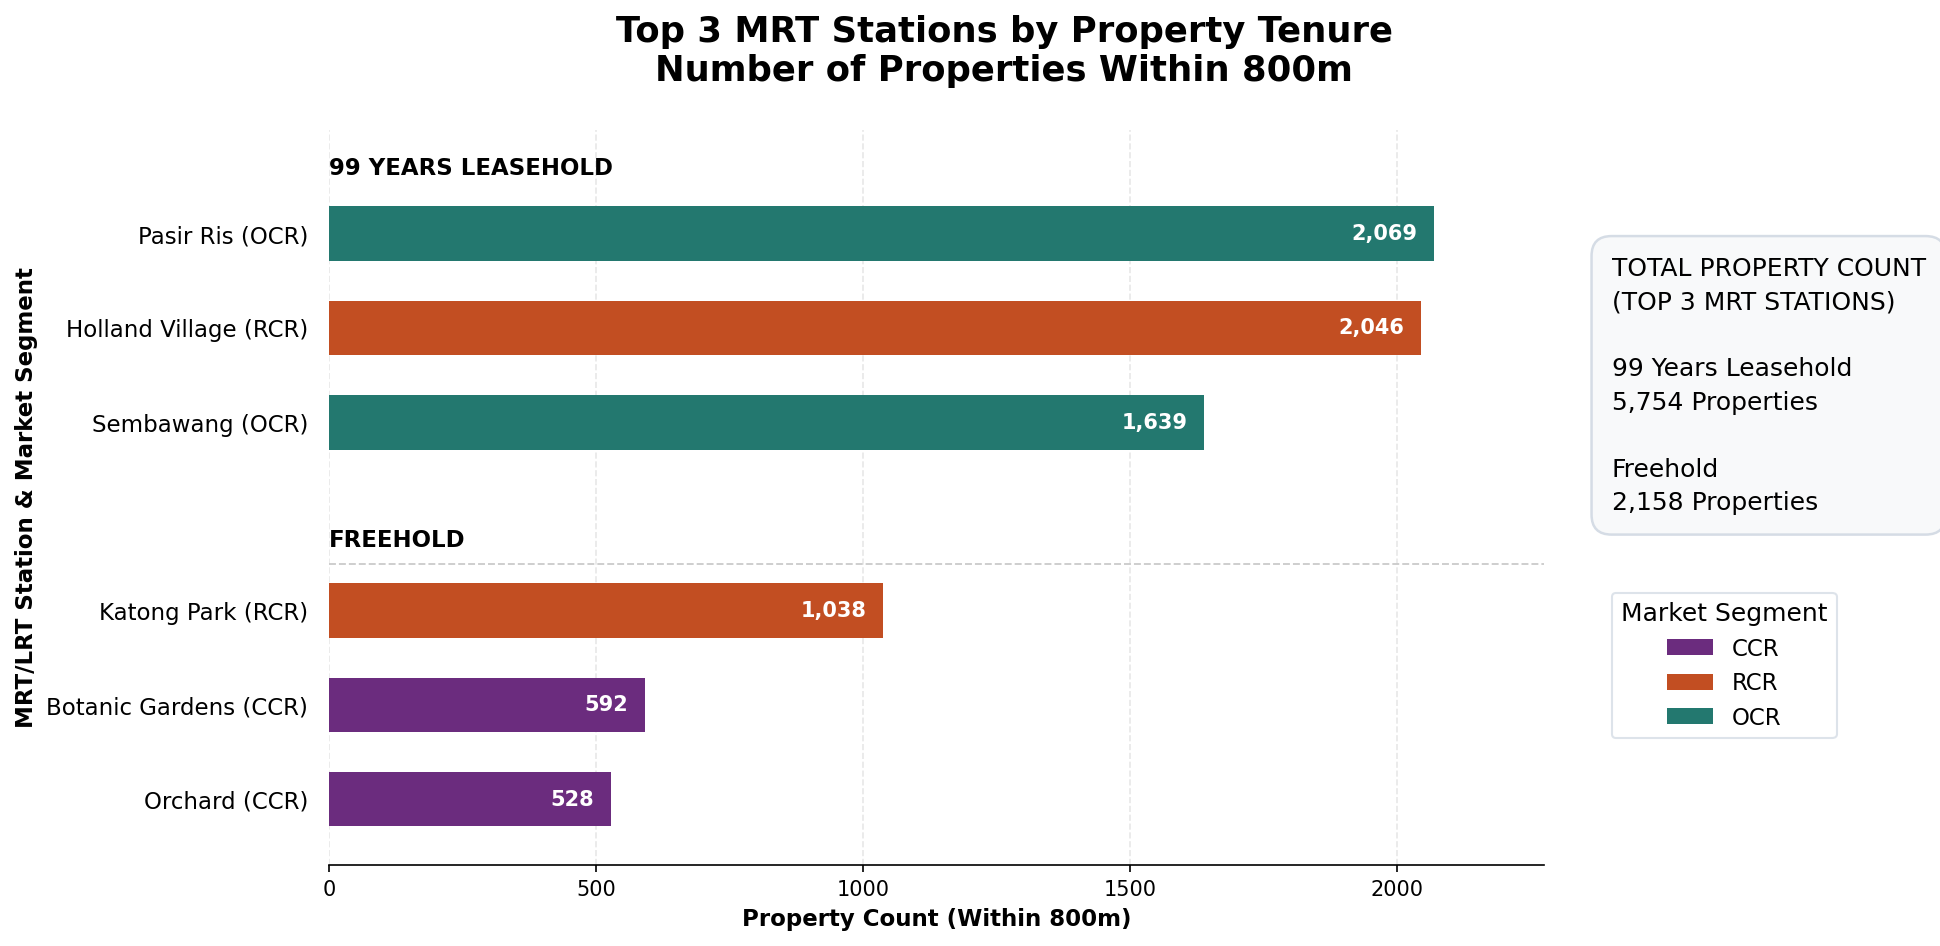

Chart saved to: /content/top_3_stations_with_tenure_totals.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [184]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from google.colab import files
import pandas as pd

# ===========================================================
# 1. PREPARE DATA
# ===========================================================

plot_data_3 = pd.DataFrame({
    'MRT/LRT Station': [
        'Pasir Ris (OCR)',
        'Holland Village (RCR)',
        'Sembawang (OCR)',
        'Katong Park (RCR)',
        'Botanic Gardens (CCR)',
        'Orchard (CCR)'
    ],
    'Property Count': [
        2069, 2046, 1639,
        1038, 592, 528
    ],
    'Tenure': [
        '99 Years Leasehold',
        '99 Years Leasehold',
        '99 Years Leasehold',
        'Freehold',
        'Freehold',
        'Freehold'
    ],
    'Segment': [
        'OCR', 'RCR', 'OCR',
        'RCR', 'CCR', 'CCR'
    ]
})

# ===========================================================
# 2. MARKET SEGMENT COLOURS
# ===========================================================

segment_colors = {
    'CCR': '#6b2c7e',
    'RCR': '#c24e22',
    'OCR': '#23786f'
}

bar_colors = plot_data_3['Segment'].map(segment_colors)

# ===========================================================
# 3. CALCULATE TOTAL PROPERTY COUNTS BY TENURE
# ===========================================================

tenure_totals = (
    plot_data_3
    .groupby('Tenure')['Property Count']
    .sum()
)

leasehold_total = tenure_totals['99 Years Leasehold']
freehold_total = tenure_totals['Freehold']

print("TOTAL PROPERTY COUNTS (TOP 3 STATIONS)")
print(f"99 Years Leasehold: {leasehold_total:,}")
print(f"Freehold: {freehold_total:,}")

# ===========================================================
# 4. CREATE HORIZONTAL BAR CHART
# ===========================================================

fig, ax = plt.subplots(
    figsize=(15, 7),
    dpi=150
)

# Leave space on the right for legends
fig.subplots_adjust(
    left=0.20,
    right=0.74,
    top=0.85,
    bottom=0.15
)

y_positions = [0, 1, 2, 4, 5, 6]

bars = ax.barh(
    y=y_positions,
    width=plot_data_3['Property Count'],
    color=bar_colors,
    height=0.58
)

ax.set_yticks(y_positions)

ax.set_yticklabels(
    plot_data_3['MRT/LRT Station'],
    fontsize=11
)

ax.set_ylim(-1.1, 6.7)
ax.invert_yaxis()

# ===========================================================
# 5. TITLE AND AXIS LABELS
# ===========================================================

fig.suptitle(
    'Top 3 MRT Stations by Property Tenure\n'
    'Number of Properties Within 800m',
    fontsize=17,
    fontweight='bold',
    y=0.96
)

ax.set_xlabel(
    'Property Count (Within 800m)',
    fontsize=11,
    fontweight='bold'
)

ax.set_ylabel(
    'MRT/LRT Station & Market Segment',
    fontsize=11,
    fontweight='bold'
)

# ===========================================================
# 6. TENURE GROUP HEADINGS
# ===========================================================

ax.text(
    0, -0.7,
    '99 YEARS LEASEHOLD',
    fontsize=11,
    fontweight='bold',
    va='center'
)

ax.text(
    0, 3.25,
    'FREEHOLD',
    fontsize=11,
    fontweight='bold',
    va='center'
)

# Divider between tenure groups
ax.axhline(
    y=3.5,
    color='#cccccc',
    linestyle='--',
    linewidth=0.9
)

# Vertical gridlines
ax.set_axisbelow(True)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

ax.set_xlim(
    0,
    plot_data_3['Property Count'].max() * 1.10
)

# ===========================================================
# 7. DISPLAY PROPERTY COUNTS INSIDE BARS
# ===========================================================

label_padding = (
    plot_data_3['Property Count'].max() * 0.015
)

for bar in bars:

    count = bar.get_width()

    ax.text(
        count - label_padding,
        bar.get_y() + bar.get_height() / 2,
        f'{int(count):,}',
        va='center',
        ha='right',
        color='white',
        fontweight='bold',
        fontsize=10
    )

# ===========================================================
# 8. TOTAL PROPERTY COUNT LEGEND (RIGHT SIDE)
# ===========================================================

total_text = (
    "TOTAL PROPERTY COUNT\n"
    "(TOP 3 MRT STATIONS)\n\n"
    f"99 Years Leasehold\n"
    f"{leasehold_total:,} Properties\n\n"
    f"Freehold\n"
    f"{freehold_total:,} Properties"
)

fig.text(
    0.77,
    0.73,
    total_text,
    fontsize=12,
    va='top',
    ha='left',
    linespacing=1.5,
    bbox=dict(
        boxstyle='round,pad=0.8',
        facecolor='#f8f9fa',
        edgecolor='#d5dce5',
        linewidth=1.2
    )
)

# ===========================================================
# 9. MARKET SEGMENT LEGEND (RIGHT SIDE)
# ===========================================================

legend_handles = [
    Patch(
        facecolor=segment_colors['CCR'],
        label='CCR'
    ),
    Patch(
        facecolor=segment_colors['RCR'],
        label='RCR'
    ),
    Patch(
        facecolor=segment_colors['OCR'],
        label='OCR'
    )
]

fig.legend(
    handles=legend_handles,
    title='Market Segment',
    loc='center left',
    bbox_to_anchor=(0.765, 0.34),
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    facecolor='white',
    edgecolor='#d5dce5'
)

# ===========================================================
# 10. CLEAN UP CHART
# ===========================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.tick_params(
    axis='y',
    length=0,
    pad=10
)

# ===========================================================
# 11. SAVE, DISPLAY AND DOWNLOAD
# ===========================================================

output_top3_path = (
    '/content/top_3_stations_with_tenure_totals.png'
)

fig.savefig(
    output_top3_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print(f"Chart saved to: {output_top3_path}")

try:
    files.download(output_top3_path)

except Exception as e:
    print(f"Automatic download could not start: {e}")
    print("Download the PNG from Colab Files.")


In [185]:
# ============================================================
# MRT EXIT DENSITY BY MARKET SEGMENT
# Number of MRT exits per square kilometre
# ============================================================

import geopandas as gpd
import pandas as pd

# Ensure variables from earlier cells exist in the namespace
if 'planning_area_gdf' not in locals() or 'mrt_with_areas' not in locals():
    print("Previous variables not found in namespace. Reloading data from GitHub to resolve NameError...")
    GITHUB_BASE = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/"

    # Load planning area boundaries
    planning_area_gdf = gpd.read_file(GITHUB_BASE + "MasterPlan2019PlanningAreaBoundaryNoSea.geojson").to_crs(epsg=4326)

    # Segment mapping logic
    ccr_areas = ['DOWNTOWN CORE', 'SINGAPORE RIVER', 'MUSEUM', 'NEWTON', 'ORCHARD', 'RIVER VALLEY', 'TANGLIN', 'MARINA EAST', 'MARINA SOUTH', 'STRAITS VIEW', 'SOUTHERN ISLANDS', 'SENTOSA']
    rcr_areas = ['QUEENSTOWN', 'ALEXANDRA', 'BUKIT MERAH', 'TELOK BLANGAH', 'DEPOT ROAD', 'OUTRAM', 'ROCHOR', 'KALLANG', 'GEYLANG', 'TOA PAYOH', 'NOVENA', 'MARINE PARADE', 'BISHAN']

    def get_segment(row):
        name = str(row['PLN_AREA_N']).upper().strip()
        if name in ccr_areas: return 'CCR'
        elif name in rcr_areas: return 'RCR'
        else: return 'OCR'

    planning_area_gdf['segment'] = planning_area_gdf.apply(get_segment, axis=1)

    # Load and filter MRT exits
    mrt_exits_gdf = gpd.read_file(GITHUB_BASE + "LTAMRTStationExitGEOJSON.geojson").to_crs(epsg=4326)
    mrt_exits_gdf = mrt_exits_gdf[mrt_exits_gdf.geometry.notna() & mrt_exits_gdf.geom_type.eq("Point")].copy()
    mrt_exits_gdf = mrt_exits_gdf[mrt_exits_gdf["STATION_NA"].astype(str).str.contains(r"\bMRT\b", case=False, na=False)].copy()

    # Perform spatial join
    mrt_with_areas = gpd.sjoin(mrt_exits_gdf, planning_area_gdf[['PLN_AREA_N', 'segment', 'geometry']], how='inner', predicate='within')

# 1. Convert planning areas to Singapore's projected CRS
# EPSG:3414 uses metres, allowing accurate area calculation
planning_metric = planning_area_gdf.to_crs(epsg=3414).copy()

# 2. Calculate the land area of each planning area (km²)
planning_metric["area_km2"] = (
    planning_metric.geometry.area / 1_000_000
)

# 3. Combine planning-area land areas by market segment
region_areas = (
    planning_metric
    .groupby("segment")["area_km2"]
    .sum()
)

# 4. Count MRT exit points in each segment
exit_counts = (
    mrt_with_areas["segment"]
    .value_counts()
)

# 5. Combine exit counts and land areas
mrt_density = pd.DataFrame({
    "MRT Exit Count": exit_counts,
    "Area (km²)": region_areas
})

mrt_density = mrt_density.reindex(
    ["CCR", "RCR", "OCR"]
)

mrt_density["MRT Exits per km²"] = (
    mrt_density["MRT Exit Count"]
    / mrt_density["Area (km²)"]
)

# 6. Display the calculations
print("=== MRT EXIT DENSITY BY MARKET SEGMENT ===")
display(mrt_density.round(2))

# 7. Identify the region with the highest density
highest = mrt_density["MRT Exits per km²"].idxmax()

print(
    f"\nRegion with highest MRT exit density: {highest}"
)

print(
    f"Density: "
    f"{mrt_density.loc[highest, 'MRT Exits per km²']:.2f} "
    "exits/km²"
)

=== MRT EXIT DENSITY BY MARKET SEGMENT ===


,MRT Exit Count,Area (km²),MRT Exits per km²
segment,,,
CCR,134,30.65,4.37
RCR,171,88.23,1.94
OCR,219,666.04,0.33



Region with highest MRT exit density: CCR
Density: 4.37 exits/km²


3.3 Proximity to Amenities

## Amenities Accessibility — Data Processing Methodology

This section documents the original data preparation, geocoding,
and distance calculation process.

Residential projects were geocoded using OneMap, with street-level
fallbacks where needed. Nearest amenity distances were calculated
using BallTree and the Haversine metric.

The geocoding and distance calculations have already been completed.
Precomputed results are available in the group's GitHub repository.

**Note:** The original calculation requires the source amenity
datasets and is included for methodology reference rather than
automatic re-execution.

```python
# DAO2702 — Accessibility: Amenities Analysis
# Steps 1–5: Data preparation, geocoding and distance calculation

import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests

from shapely.geometry import shape
from sklearn.neighbors import BallTree

# ==========================================
# 1. FILES AND RESIDENTIAL PROJECTS
# ==========================================

BASE = Path('/content')
OUT = Path('/content/drive/MyDrive/DAO2702_Amenities')
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    'properties': 'properties2025_cleaned.csv',
    'hawker': 'HawkerCentresGEOJSON.geojson',
    'supermarket': 'ListofSupermarketLicences.csv',
    'mall': 'shopping_malls.geojson',
    'park': 'parks.geojson',
    'healthcare': 'hospitals.geojson'
}

for key, filename in FILES.items():
    if not (BASE / filename).exists():
        raise FileNotFoundError(
            f'Missing file: {filename}. Please upload it first.'
        )

raw = pd.read_csv(BASE / FILES['properties'])

required = ['project', 'street', 'district', 'segment']

projects = (
    raw.loc[
        raw['segment'].isin(['CCR', 'RCR', 'OCR']),
        required
    ]
    .dropna(subset=['project', 'street'])
    .drop_duplicates()
    .reset_index(drop=True)
)

projects['key'] = projects[required].astype(str).agg('|'.join, axis=1)

projects.to_csv(OUT / 'sample_projects.csv', index=False)

print('Total projects:', len(projects), flush=True)
print(projects['segment'].value_counts(), flush=True)


# ==========================================
# 2. READ EXTERNAL GEOJSON DATA
# ==========================================

def geojson_points(path):
    with open(path, encoding='utf-8') as f:
        data = json.load(f)

    features = data.get('features', [])
    output = []

    for feature in features:
        geometry = feature.get('geometry')

        if not geometry:
            continue

        try:
            g = shape(geometry)

            if g.is_empty:
                continue

            point = (
                g if g.geom_type == 'Point'
                else g.representative_point()
            )

            lat = float(point.y)
            lon = float(point.x)

            # Initial bounding-box filter
            if 1.15 <= lat <= 1.48 and 103.60 <= lon <= 104.10:
                props = feature.get('properties') or {}

                output.append({
                    'lat': lat,
                    'lon': lon,
                    'name': str(props.get('name', ''))
                })

        except Exception:
            continue

    return (
        pd.DataFrame(
            output,
            columns=['lat', 'lon', 'name']
        )
        .drop_duplicates(subset=['lat', 'lon'])
        .reset_index(drop=True)
    )


hawker = geojson_points(BASE / FILES['hawker'])
mall = geojson_points(BASE / FILES['mall'])
park = geojson_points(BASE / FILES['park'])
healthcare = geojson_points(BASE / FILES['healthcare'])

super_raw = pd.read_csv(
    BASE / FILES['supermarket'],
    dtype=str,
    encoding='utf-8-sig'
)

postal_cols = [
    c for c in super_raw.columns
    if 'postal' in c.lower()
]

if not postal_cols:
    raise ValueError(
        'Cannot find supermarket postal-code column.'
    )

postal_col = postal_cols[0]

super_codes = (
    super_raw[postal_col]
    .fillna('')
    .astype(str)
    .str.extract(r'(\d{6})')[0]
    .dropna()
    .drop_duplicates()
    .tolist()
)

print('Hawker centres:', len(hawker), flush=True)
print('Shopping malls:', len(mall), flush=True)
print('Parks:', len(park), flush=True)
print('Healthcare locations:', len(healthcare), flush=True)
print('Supermarket postal codes:', len(super_codes), flush=True)


# ==========================================
# 3. GEOCODING WITH GOOGLE DRIVE CACHE
# ==========================================

session = requests.Session()

session.headers.update({
    'User-Agent': 'DAO2702-Student-Amenities-Analysis/1.0'
})

CACHE = OUT / 'geocoding_cache.csv'

if CACHE.exists():
    cache = pd.read_csv(CACHE, dtype={'query': str})
    cache = cache.drop_duplicates('query', keep='last')
else:
    cache = pd.DataFrame(
        columns=['query', 'lat', 'lon', 'source']
    )

lookup = {
    row['query']: (
        row['lat'],
        row['lon'],
        row['source']
    )
    for _, row in cache.iterrows()
}


def search_onemap(query):
    url = 'https://www.onemap.gov.sg/api/common/elastic/search'

    for attempt in range(3):
        try:
            response = session.get(
                url,
                params={
                    'searchVal': query,
                    'returnGeom': 'Y',
                    'getAddrDetails': 'Y',
                    'pageNum': 1
                },
                timeout=20
            )

            if response.status_code == 429:
                time.sleep(3 * (attempt + 1))
                continue

            response.raise_for_status()

            results = response.json().get('results', [])

            if results:
                result = results[0]

                lat = float(result['LATITUDE'])
                lon = float(result['LONGITUDE'])

                if (
                    1.15 <= lat <= 1.48
                    and 103.60 <= lon <= 104.10
                ):
                    return lat, lon

            return np.nan, np.nan

        except (requests.RequestException, ValueError, KeyError):
            time.sleep(2 * (attempt + 1))

    return np.nan, np.nan


def geocode(query):
    query = str(query).strip()

    if query in lookup:
        lat, lon, _ = lookup[query]

        return (
            float(lat) if pd.notna(lat) else np.nan,
            float(lon) if pd.notna(lon) else np.nan
        )

    lat, lon = search_onemap(query)

    lookup[query] = (lat, lon, 'OneMap')

    return lat, lon


def save_cache():
    records = [
        {
            'query': key,
            'lat': value[0],
            'lon': value[1],
            'source': value[2]
        }
        for key, value in lookup.items()
    ]

    pd.DataFrame(records).to_csv(CACHE, index=False)


# Geocode residential projects
coordinates = []

for i, row in projects.iterrows():

    lat, lon = geocode(row['project'])
    method = 'project'

    if not np.isfinite(lat):
        lat, lon = geocode(row['street'])
        method = 'street_fallback'

    coordinates.append((lat, lon, method))

    if (i + 1) % 50 == 0:
        save_cache()

        print(
            f'Geocoded projects: {i + 1}/{len(projects)}',
            flush=True
        )

    time.sleep(0.15)

save_cache()

projects[['lat', 'lon', 'geocode_method']] = (
    pd.DataFrame(coordinates, index=projects.index)
)

projects.to_csv(
    OUT / 'residential_projects_geocoded.csv',
    index=False
)

print(
    'Successfully geocoded:',
    projects['lat'].notna().sum(),
    '/',
    len(projects),
    flush=True
)


# Geocode supermarket postal codes
supermarket_coordinates = []

for i, code in enumerate(super_codes):

    lat, lon = geocode(code)

    if np.isfinite(lat):
        supermarket_coordinates.append({
            'lat': lat,
            'lon': lon,
            'name': code
        })

    if (i + 1) % 50 == 0:
        save_cache()

        print(
            f'Supermarket postal codes: {i + 1}/{len(super_codes)}',
            flush=True
        )

    time.sleep(0.15)

save_cache()

supermarket = (
    pd.DataFrame(
        supermarket_coordinates,
        columns=['lat', 'lon', 'name']
    )
    .drop_duplicates(subset=['lat', 'lon'])
)


# ==========================================
# 4. COMBINE FACILITY CATEGORIES
# ==========================================

facilities = {
    'Food': hawker,

    'Shopping': (
        pd.concat(
            [mall, supermarket],
            ignore_index=True
        )
        .drop_duplicates(subset=['lat', 'lon'])
    ),

    'Leisure': park,

    'Healthcare': healthcare
}

print('\nFacility counts:', flush=True)

for category, data in facilities.items():
    print(category, len(data), flush=True)

if any(len(data) == 0 for data in facilities.values()):
    raise ValueError(
        'One or more facility categories are empty.'
    )


# ==========================================
# 5. CALCULATE NEAREST AMENITY DISTANCES
# ==========================================

valid = projects.dropna(
    subset=['lat', 'lon']
).copy()

for category, data in facilities.items():

    tree = BallTree(
        np.radians(
            data[['lat', 'lon']].to_numpy(float)
        ),
        metric='haversine'
    )

    distances, indices = tree.query(
        np.radians(
            valid[['lat', 'lon']].to_numpy(float)
        ),
        k=1
    )

    valid[category + '_km'] = (
        distances[:, 0] * 6371.0088
    )


# Save individual project distances
valid.to_csv(
    OUT / 'amenities_project_distances.csv',
    index=False
)


# Calculate median distances by region
summary = (
    valid.groupby('segment')[
        [category + '_km' for category in facilities]
    ]
    .median()
    .reindex(['CCR', 'RCR', 'OCR'])
)

summary.columns = list(facilities)

summary.to_csv(
    OUT / 'amenities_median_distances_km.csv'
)

print('\nMedian distances (km):', flush=True)
print(summary.round(3), flush=True)

print('\nSTEPS 1–5 COMPLETED!', flush=True)
print('Results saved to:', OUT, flush=True)
```

In [186]:

import pandas as pd

# Load saved results from the group GitHub repository
base_url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/Amenities_Accessibility/"

projects = pd.read_csv(base_url + "residential_projects_geocoded.csv")
distances = pd.read_csv(base_url + "amenities_project_distances.csv")

distance_cols = ["Food_km", "Shopping_km", "Leisure_km", "Healthcare_km"]

print("===== GEOCODING RESULTS =====")
print("Total projects:", len(projects))
print("Successfully geocoded:", projects["lat"].notna().sum())

print("\nGeocoding methods:")
print(projects["geocode_method"].value_counts())

print("\n===== PROJECTS BY REGION =====")
print(distances["segment"].value_counts())

print("\n===== MEDIAN DISTANCES (KM) =====")
summary_check = (
    distances.groupby("segment")[distance_cols]
    .median()
    .reindex(["CCR", "RCR", "OCR"])
)
display(summary_check.round(3))

print("\n===== DISTANCE QUALITY CHECK =====")
print("Projects with any distance above 5 km:",
      (distances[distance_cols] > 5).any(axis=1).sum())


===== GEOCODING RESULTS =====
Total projects: 1793
Successfully geocoded: 1792

Geocoding methods:
geocode_method
project            1749
street_fallback      44
Name: count, dtype: int64

===== PROJECTS BY REGION =====
segment
RCR    661
OCR    600
CCR    531
Name: count, dtype: int64

===== MEDIAN DISTANCES (KM) =====


,Food_km,Shopping_km,Leisure_km,Healthcare_km
segment,,,,
CCR,0.673,0.290,0.385,0.475
RCR,0.542,0.327,0.270,0.341
OCR,0.865,0.437,0.272,0.471



===== DISTANCE QUALITY CHECK =====
Projects with any distance above 5 km: 0


In [187]:

url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/Amenities_Accessibility/amenities_project_distances.csv"

df = pd.read_csv(url)

print("Projects included in distance analysis:")
print(df['segment'].value_counts())

print("\nUnique coordinate locations:")
print(
    df.groupby('segment')
      .apply(lambda x: x[['lat', 'lon']].drop_duplicates().shape[0])
)

print("\nProjects with identical coordinates:")
print(
    df.duplicated(subset=['lat', 'lon'], keep=False).sum()
)

print("\nProjects with zero or near-zero distances (< 0.01 km):")
for col in ['Food_km', 'Shopping_km', 'Leisure_km', 'Healthcare_km']:
    print(col, (df[col] < 0.01).sum())


Projects included in distance analysis:
segment
RCR    661
OCR    600
CCR    531
Name: count, dtype: int64

Unique coordinate locations:
segment
CCR    522
OCR    594
RCR    656
dtype: int64

Projects with identical coordinates:
44

Projects with zero or near-zero distances (< 0.01 km):
Food_km 2
Shopping_km 18
Leisure_km 1
Healthcare_km 2


/tmp/ipykernel_1410/3231684534.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x[['lat', 'lon']].drop_duplicates().shape[0])


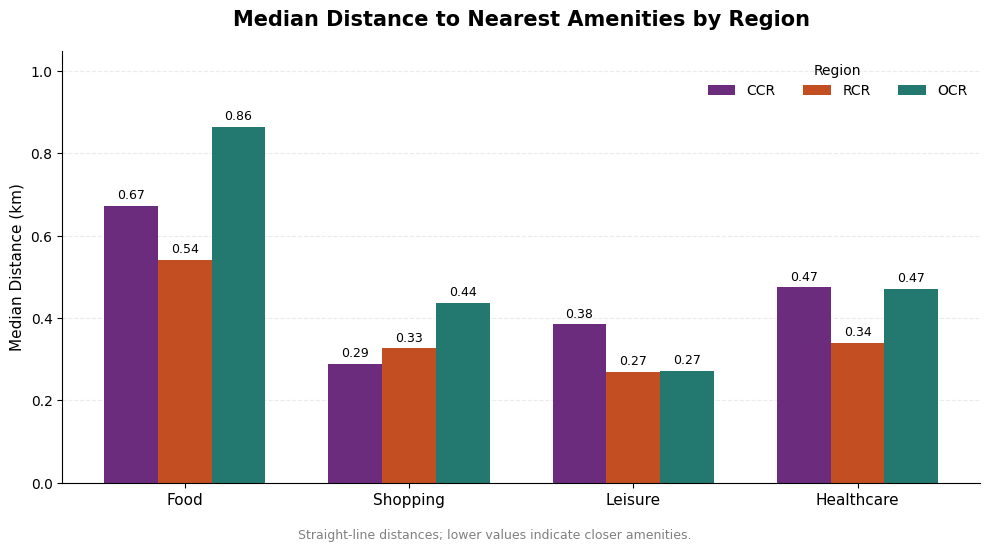

In [188]:



import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data from group GitHub
url = "https://raw.githubusercontent.com/hawflakess/DAO2702-Group-Assignment/main/Amenities_Accessibility/amenities_median_distances_km.csv"

summary = pd.read_csv(url, index_col=0)


regions = ['CCR', 'RCR', 'OCR']
categories = ['Food', 'Shopping', 'Leisure', 'Healthcare']


# Chart settings
x = np.arange(len(categories))
width = 0.24

colors = {
    'CCR': '#6B2C7E',
    'RCR': '#C24E22',
    'OCR': '#23786F'
}

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, region in enumerate(regions):
    bars = ax.bar(
        x + (i - 1) * width,
        summary.loc[region].values,
        width,
        label=region,
        color=colors[region]
    )

    ax.bar_label(
        bars,
        fmt='%.2f',
        padding=3,
        fontsize=9
    )

ax.set_title(
    'Median Distance to Nearest Amenities by Region',
    fontsize=15,
    fontweight='bold',
    pad=18
)

ax.set_ylabel('Median Distance (km)', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11)

ax.set_ylim(0, 1.05)
ax.legend(title='Region', frameon=False, ncol=3)

ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.figtext(
    0.5, 0.01,
    'Straight-line distances; lower values indicate closer amenities.',
    ha='center',
    fontsize=9,
    color='gray'
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save chart
plt.savefig(
    '/content/amenities_grouped_bar_chart.png',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    '/content/amenities_grouped_bar_chart.pdf',
    bbox_inches='tight'
)

#4. Price Growth and Market Dynamics



4.1 Quarterly Resale Price Growth by Area
Our combined property dataset contains transaction date, sale type, tenure, market segment, price and area. The code below filters for freehold and 99-year leasehold resale properties, calculates quarterly median PSF, indexes each area to its first available 2021 quarter, and plots price-growth trends for OCR, RCR and CCR.

In [189]:
import pandas as pd

# Load the three cleaned datasets directly from GitHub
base_url = (
    "https://raw.githubusercontent.com/"
    "hawflakess/DAO2702-Group-Assignment/main/"
)

df_2021_2023 = pd.read_csv(base_url + "properties23.csv")
df_2024 = pd.read_csv(base_url + "properties2024.csv")
df_2025 = pd.read_csv(base_url + "properties2025_cleaned.csv")

# Combine 2021–2025 data
df_2021_2025 = pd.concat(
    [df_2021_2023, df_2024, df_2025],
    ignore_index=True
)

# Create a usable date column for time-based graphs
df_2021_2025["date_parsed"] = pd.to_datetime(
    df_2021_2025["date"],
    format="%b-%y",
    errors="coerce"
)

print("Combined shape:", df_2021_2025.shape)
print(df_2021_2025["date_parsed"].dt.year.value_counts().sort_index())

Combined shape: (118615, 13)
date_parsed
2020    10306
2021    28883
2022    18924
2023    16458
2024    19893
2025    24151
Name: count, dtype: int64


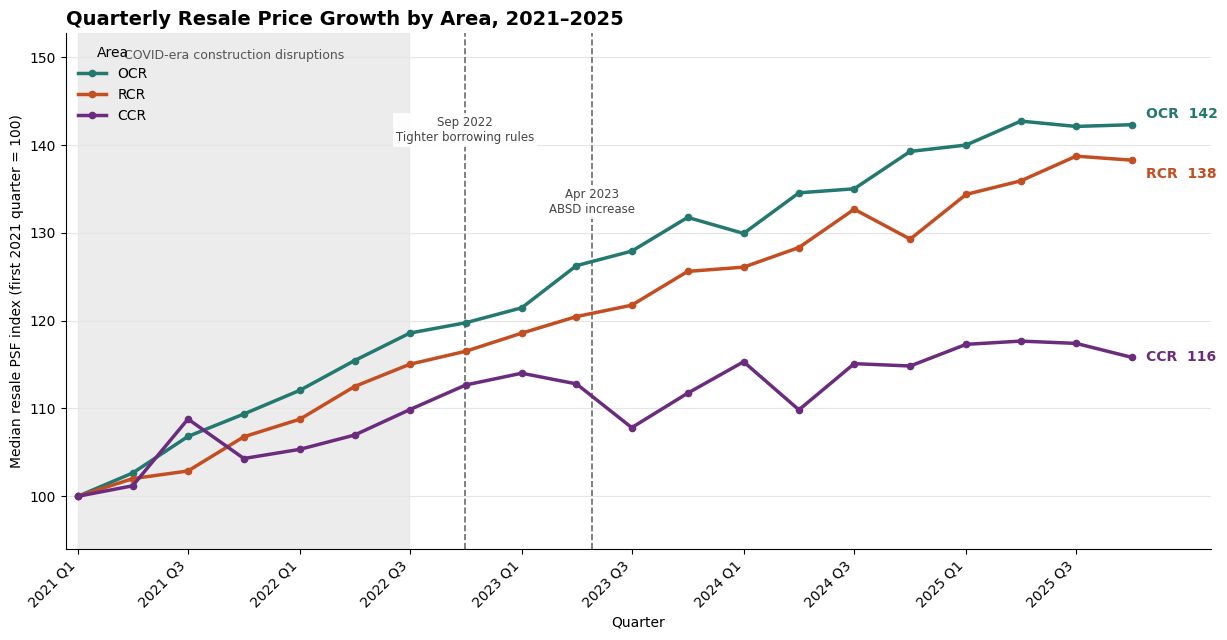

In [190]:
# Quarterly resale price timeline by area
# Freehold and 99-year resale properties only, 2021 onwards

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Filter to resale, freehold and 99-year leasehold transactions
resale = df_2021_2025.loc[
    df_2021_2025["sale"].eq("Resale")
].copy()

resale["tenure_clean"] = (
    resale["tenure"].astype(str).str.strip().str.lower()
)

resale = resale.loc[
    resale["tenure_clean"].isin(["freehold", "99 years"])
].copy()

# Convert variables and calculate PSF
resale["price"] = pd.to_numeric(resale["price"], errors="coerce")
resale["area"] = pd.to_numeric(resale["area"], errors="coerce")
resale["date_parsed"] = pd.to_datetime(
    resale["date"], format="%b-%y", errors="coerce"
)

resale["psf"] = resale["price"] / resale["area"]

resale = resale.loc[
    resale["date_parsed"].dt.year.ge(2021)
    & resale["area"].gt(0)
    & resale["psf"].gt(0)
].dropna(subset=["date_parsed", "segment", "psf"]).copy()

# Create quarterly median PSF and index first available 2021 quarter to 100
resale["quarter"] = resale["date_parsed"].dt.to_period("Q")
segments = ["OCR", "RCR", "CCR"]

quarterly_psf = (
    resale.groupby(["quarter", "segment"])["psf"]
    .median()
    .unstack()
    .reindex(columns=segments)
    .sort_index()
)

quarterly_index = quarterly_psf.copy()

for segment in segments:
    base_value = quarterly_psf.loc[
        quarterly_psf.index.year == 2021, segment
    ].dropna().iloc[0]

    quarterly_index[segment] = quarterly_psf[segment] / base_value * 100

plot_dates = quarterly_index.index.to_timestamp()

# Colours
segment_colors = {
    "CCR": "#6b2c7e",
    "RCR": "#c24e22",
    "OCR": "#23786f"
}

end_offsets = {
    "OCR": (10, 8),
    "RCR": (10, -10),
    "CCR": (10, 0)
}

# Plot
fig, ax = plt.subplots(figsize=(12.5, 6.5))

ax.axvspan(
    pd.Timestamp("2021-01-01"),
    pd.Timestamp("2022-06-30"),
    color="#e5e5e5",
    alpha=0.7,
    zorder=0
)

ax.text(
    pd.Timestamp("2021-09-15"),
    0.97,
    "COVID-era construction disruptions",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=9,
    color="#555555"
)

for segment in segments:
    ax.plot(
        plot_dates,
        quarterly_index[segment],
        color=segment_colors[segment],
        marker="o",
        markersize=4.5,
        linewidth=2.5,
        label=segment,
        zorder=3
    )

    end_value = quarterly_index[segment].iloc[-1]

    ax.annotate(
        f"{segment}  {end_value:.0f}",
        xy=(plot_dates[-1], end_value),
        xytext=end_offsets[segment],
        textcoords="offset points",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=segment_colors[segment]
    )

# Policy events
events = [
    (pd.Timestamp("2022-09-30"), "Sep 2022\nTighter borrowing rules", 0.84),
    (pd.Timestamp("2023-04-27"), "Apr 2023\nABSD increase", 0.70)
]

for event_date, label, y_position in events:
    ax.axvline(
        event_date,
        color="#6b6b6b",
        linestyle="--",
        linewidth=1.2,
        zorder=1
    )

    ax.text(
        event_date,
        y_position,
        label,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=8.5,
        color="#444444",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=2)
    )

# Formatting
ax.set_title(
    "Quarterly Resale Price Growth by Area, 2021–2025",
    loc="left",
    fontweight="bold",
    fontsize=14
)

ax.set_ylabel("Median resale PSF index (first 2021 quarter = 100)")
ax.set_xlabel("Quarter")

ax.set_xticks(plot_dates[::2])
ax.set_xticklabels(
    [f"{p.year} Q{p.quarter}" for p in quarterly_index.index[::2]],
    rotation=45,
    ha="right"
)

ax.set_ylim(94, quarterly_index.max().max() + 10)
ax.set_xlim(
    plot_dates[0] - pd.Timedelta(days=20),
    plot_dates[-1] + pd.Timedelta(days=130)
)

ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Area", frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

fig.savefig(
    "quarterly_resale_index_freehold_99year.png",
    dpi=300,
    bbox_inches="tight"
)

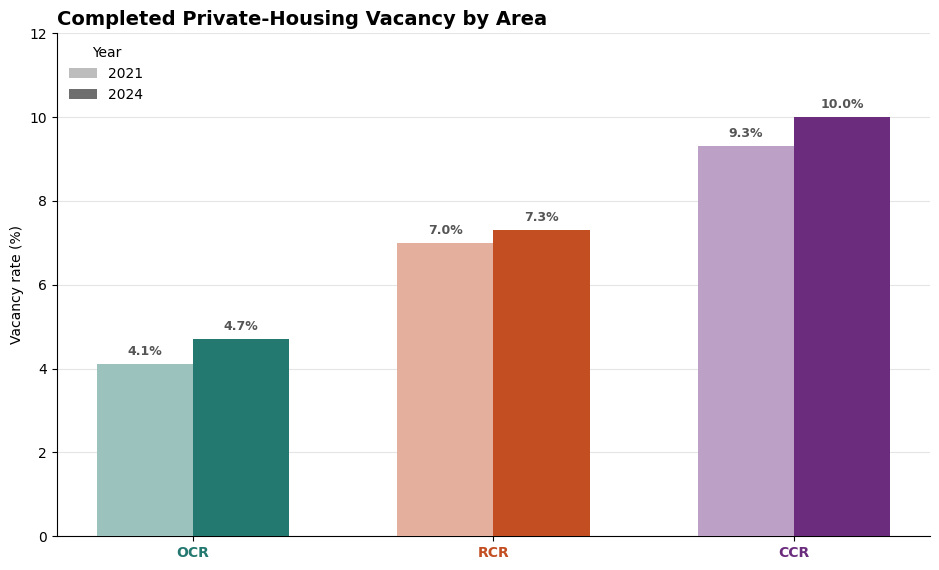

In [191]:
# Completed private-housing vacancy by area
# Data loaded directly from the group GitHub repository

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from IPython.display import display, Markdown

# Load vacancy data from GitHub
vacancy_url = (
    "https://raw.githubusercontent.com/"
    "hawflakess/DAO2702-Group-Assignment/main/"
    "vacancy_rates_CCR_RCR_OCR_2021_2024.csv"
)

vacancy_df = pd.read_csv(vacancy_url)

# Extract year from values such as "2021 Q4"
vacancy_df["year"] = (
    vacancy_df["quarter"]
    .str.extract(r"(\d{4})")[0]
    .astype(int)
)

# Prepare chart data
area_order = ["OCR", "RCR", "CCR"]

vacancy_plot = (
    vacancy_df
    .pivot(index="area", columns="year", values="vacancy_rate_percent")
    .reindex(area_order)
)

segment_colors = {
    "CCR": "#6b2c7e",
    "RCR": "#c24e22",
    "OCR": "#23786f"
}

def lighten_colour(hex_colour, strength=0.45):
    red, green, blue = to_rgb(hex_colour)
    return (
        1 - (1 - red) * strength,
        1 - (1 - green) * strength,
        1 - (1 - blue) * strength
    )

# Plot
fig, ax = plt.subplots(figsize=(9.5, 5.8))

x = np.arange(len(area_order))
bar_width = 0.32

for i, area in enumerate(area_order):
    value_2021 = vacancy_plot.loc[area, 2021]
    value_2024 = vacancy_plot.loc[area, 2024]

    ax.bar(
        x[i] - bar_width / 2,
        value_2021,
        width=bar_width,
        color=lighten_colour(segment_colors[area]),
        zorder=3
    )

    ax.bar(
        x[i] + bar_width / 2,
        value_2024,
        width=bar_width,
        color=segment_colors[area],
        zorder=3
    )

    # Value labels
    ax.text(
        x[i] - bar_width / 2,
        value_2021 + 0.15,
        f"{value_2021:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color="#555555"
    )

    ax.text(
        x[i] + bar_width / 2,
        value_2024 + 0.15,
        f"{value_2024:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color="#555555"
    )

# Format
ax.set_title(
    "Completed Private-Housing Vacancy by Area",
    loc="left",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Vacancy rate (%)")
ax.set_xticks(x)
ax.set_xticklabels(area_order, fontweight="bold")
for label, area in zip(ax.get_xticklabels(), area_order):
    label.set_color(segment_colors[area])
ax.set_ylim(0, 12)

ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

# Grey legend boxes, matching the poster
legend_items = [
    Patch(facecolor="#bdbdbd", label="2021"),
    Patch(facecolor="#6e6e6e", label="2024")
]

ax.legend(
    handles=legend_items,
    title="Year",
    frameon=False,
    loc="upper left"
)
plt.tight_layout()
plt.show()

fig.savefig(
    "vacancy_rates_by_area_2021_2024.png",
    dpi=300,
    bbox_inches="tight"
)

4.3 ABSD Before-and-After Analysis

Our ABSD dataset contains quarter, market_segment and price_index. The code below calculates quarter-on-quarter growth, compares two equal five-quarter periods, and creates the three-row heatmap.

In [192]:
#4.3.1 Data loading and processing


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from urllib.parse import quote

# Consistent regional colour scheme
COLORS = {
    "CCR": "#6b2c7e",
    "RCR": "#c24e22",
    "OCR": "#23786f"
}
REGIONS = ["CCR", "RCR", "OCR"]

# Load the URA non-landed property price index from GitHub
base_url = (
    "https://raw.githubusercontent.com/"
    "hawflakess/DAO2702-Group-Assignment/main/"
)

ppi_file = "PropertyPriceIndexofNonlandedPropertiesbyLocalityQuarterly (1).csv"
ppi_df = pd.read_csv(base_url + quote(ppi_file))

# Standardise column names and regional labels
ppi_df.columns = ppi_df.columns.str.strip().str.lower()

region_map = {
    "Core Central Region": "CCR",
    "Rest of Central Region": "RCR",
    "Outside Central Region": "OCR",
    "CCR": "CCR",
    "RCR": "RCR",
    "OCR": "OCR"
}

ppi_df["market_segment"] = (
    ppi_df["market_segment"].astype(str).str.strip().replace(region_map)
)

ppi_df["price_index"] = pd.to_numeric(
    ppi_df["price_index"], errors="coerce"
)

# Convert '2023-Q2' into a quarterly Period
ppi_df["quarter"] = pd.PeriodIndex(
    ppi_df["quarter"].astype(str).str.replace("-", "", regex=False),
    freq="Q"
)

ppi_df = (
    ppi_df[ppi_df["market_segment"].isin(REGIONS)]
    .dropna(subset=["price_index"])
    .sort_values(["market_segment", "quarter"])
    .copy()
)

# Calculate quarter-on-quarter percentage growth
ppi_df["qoq_growth"] = (
    ppi_df.groupby("market_segment")["price_index"]
    .pct_change(fill_method=None) * 100
)

# Define equal five-quarter comparison windows
# ABSD increased on 27 April 2023; exclude 2023Q2.
before = ppi_df[
    ppi_df["quarter"].between(
        pd.Period("2022Q1"), pd.Period("2023Q1")
    )
]

after = ppi_df[
    ppi_df["quarter"].between(
        pd.Period("2023Q3"), pd.Period("2024Q3")
    )
]

absd_summary = pd.DataFrame({
    "Before ABSD": before.groupby("market_segment")["qoq_growth"].mean(),
    "After ABSD": after.groupby("market_segment")["qoq_growth"].mean()
}).reindex(REGIONS)

# Difference in percentage points, NOT percentage change
absd_summary["Change"] = (
    absd_summary["After ABSD"] - absd_summary["Before ABSD"]
)

print("Average quarterly price-index growth (%)")
display(absd_summary.round(3))


Average quarterly price-index growth (%)


,Before ABSD,After ABSD,Change
market_segment,,,
CCR,1.118,0.627,-0.491
RCR,2.802,0.798,-2.005
OCR,2.217,2.084,-0.133


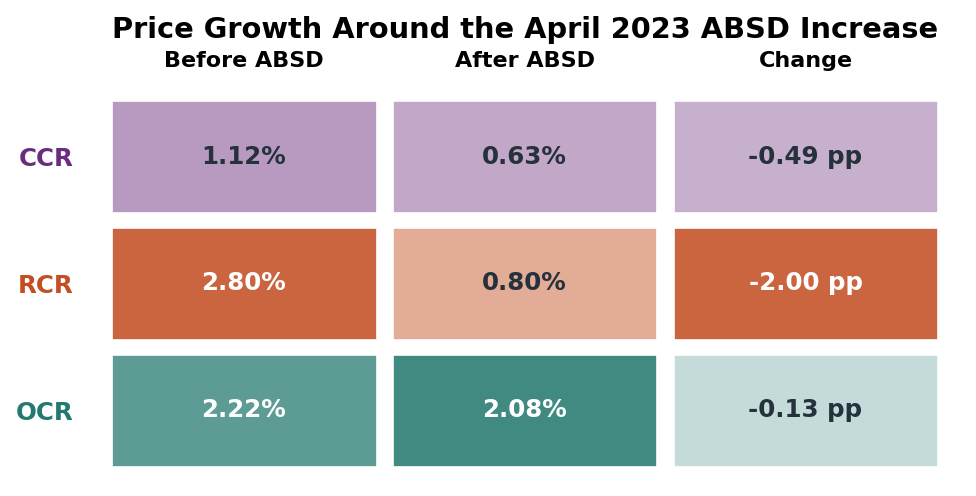

In [193]:
#4.3.2 Heatmap visualisation


from matplotlib.colors import to_rgb

def blend_with_white(hex_color, strength):
    """Create a lighter shade of the region's colour."""
    rgb = np.array(to_rgb(hex_color))
    return tuple(1 - strength * (1 - rgb))

fig, ax = plt.subplots(figsize=(6.2, 3.2), dpi=160)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

columns = ["Before ABSD", "After ABSD", "Change"]

# Colour strength is relative within each column.
# The change column uses absolute magnitude.
for j, col in enumerate(columns):
    magnitudes = absd_summary[col].abs()
    max_magnitude = magnitudes.max()

    for i, region in enumerate(REGIONS):
        value = absd_summary.loc[region, col]

        strength = (
            0.22 + 0.65 * abs(value) / max_magnitude
            if max_magnitude > 0 else 0.22
        )

        cell_color = blend_with_white(
            COLORS[region], strength
        )

        ax.add_patch(
            Rectangle(
                (j - 0.48, i - 0.46),
                0.96, 0.92,
                facecolor=cell_color,
                edgecolor="white",
                linewidth=3
            )
        )

        # Dark text on light cells, white on dark cells
        brightness = np.dot(
            cell_color, [0.299, 0.587, 0.114]
        )
        text_color = "white" if brightness < 0.60 else "#25313b"

        label = (
            f"{value:+.2f} pp"
            if col == "Change"
            else f"{value:.2f}%"
        )

        ax.text(
            j, i, label,
            ha="center", va="center",
            fontsize=11, fontweight="bold",
            color=text_color
        )

# Column labels at the top
ax.set_xticks(range(3))
ax.set_xticklabels(columns, fontsize=10, fontweight="bold")
ax.xaxis.tick_top()

# Region labels in matching colours
ax.set_yticks(range(3))
ax.set_yticklabels(REGIONS, fontsize=11, fontweight="bold")

for tick, region in zip(ax.get_yticklabels(), REGIONS):
    tick.set_color(COLORS[region])

ax.set_xlim(-0.55, 2.55)
ax.set_ylim(2.55, -0.55)
ax.tick_params(axis="both", length=0, pad=7)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Price Growth Around the April 2023 ABSD Increase",
    fontsize=13, fontweight="bold", pad=22
)

plt.tight_layout()
plt.savefig(
    "4_3_ABSD_Heatmap.png",
    dpi=300, bbox_inches="tight", facecolor="white"
)
plt.show()


4.4 SORA Interest Rates vs Property Price Growth

Our SORA CSV is a MAS daily interest-rate export, with a 3-month Compounded SORA column and year/month/day fields. It also has repeated headings, so we need to clean it before calculating quarterly averages.

In [194]:
#4.4.1 SORA data loading and processing


from io import StringIO

# Load MAS Domestic Interest Rates CSV from GitHub
sora_file = "Domestic Interest Rates.csv"
sora_url = base_url + quote(sora_file)

# Read raw text because MAS CSV has metadata and repeated headers
import requests
response = requests.get(sora_url, timeout=30)
response.raise_for_status()

# Extract only rows containing 5 comma-separated fields
# Format: Year, Month, Day, Publication Date, 3-month SORA
records = []

for line in response.text.splitlines():
    parts = line.strip().split(",")

    if len(parts) != 5:
        continue

    records.append(parts)

sora_df = pd.DataFrame(
    records,
    columns=[
        "year", "month", "day",
        "publication_date", "sora"
    ]
)

# Remove repeated table headings before filling missing dates
sora_df = sora_df[
    ~sora_df["year"].str.contains(
        "SORA Value Date", case=False, na=False
    )
].copy()

# MAS displays year/month only at the first relevant row.
# Fill them down for subsequent daily observations.
sora_df["year"] = sora_df["year"].replace("", np.nan).ffill()
sora_df["month"] = sora_df["month"].replace("", np.nan).ffill()

# Convert to numeric
sora_df["year"] = pd.to_numeric(
    sora_df["year"], errors="coerce"
)
sora_df["day"] = pd.to_numeric(
    sora_df["day"], errors="coerce"
)
sora_df["sora"] = pd.to_numeric(
    sora_df["sora"], errors="coerce"
)

# Build dates from the SORA value date (not publication date)
sora_df["date"] = pd.to_datetime(
    sora_df["year"].astype("Int64").astype(str) + "-" +
    sora_df["month"].astype(str) + "-" +
    sora_df["day"].astype("Int64").astype(str),
    format="%Y-%b-%d",
    errors="coerce"
)

sora_df = sora_df.dropna(subset=["date", "sora"]).copy()

# Restrict to 2021–2025
sora_df = sora_df[
    sora_df["date"].dt.year.between(2021, 2025)
].copy()

# Calculate average 3-month Compounded SORA per quarter
sora_df["quarter"] = sora_df["date"].dt.to_period("Q")

quarterly_sora = (
    sora_df.groupby("quarter", as_index=False)["sora"]
    .mean()
    .rename(columns={"sora": "avg_sora"})
)

print("Quarterly average 3-month Compounded SORA (%)")
display(quarterly_sora.head())


Quarterly average 3-month Compounded SORA (%)


,quarter,avg_sora
0,2021Q1,0.188750
1,2021Q2,0.173311
2,2021Q3,0.131564
3,2021Q4,0.156880
4,2022Q1,0.222752


In [195]:
#4.4.2 Merge SORA and price-growth data


# Use the URA price-index growth calculated in Section 4.3.
# Keep only 2021–2025 observations.
price_growth = ppi_df[
    ppi_df["quarter"].between(
        pd.Period("2021Q1"), pd.Period("2025Q4")
    )
][["quarter", "market_segment", "qoq_growth"]].copy()

# Match each quarter's SORA average with its URA price growth
merged_df = pd.merge(
    price_growth,
    quarterly_sora,
    on="quarter",
    how="inner"
)

merged_df = merged_df.dropna(
    subset=["qoq_growth", "avg_sora"]
).sort_values(["market_segment", "quarter"])

# Calculate Pearson correlation for each region
correlations = (
    merged_df.groupby("market_segment")
    .apply(
        lambda group: group["avg_sora"].corr(
            group["qoq_growth"]
        ),
        include_groups=False
    )
    .reindex(REGIONS)
)

print("Pearson correlation: SORA vs quarterly price growth")
display(correlations.round(4))


Pearson correlation: SORA vs quarterly price growth


,0
market_segment,
CCR,0.0200
RCR,-0.3250
OCR,-0.1018


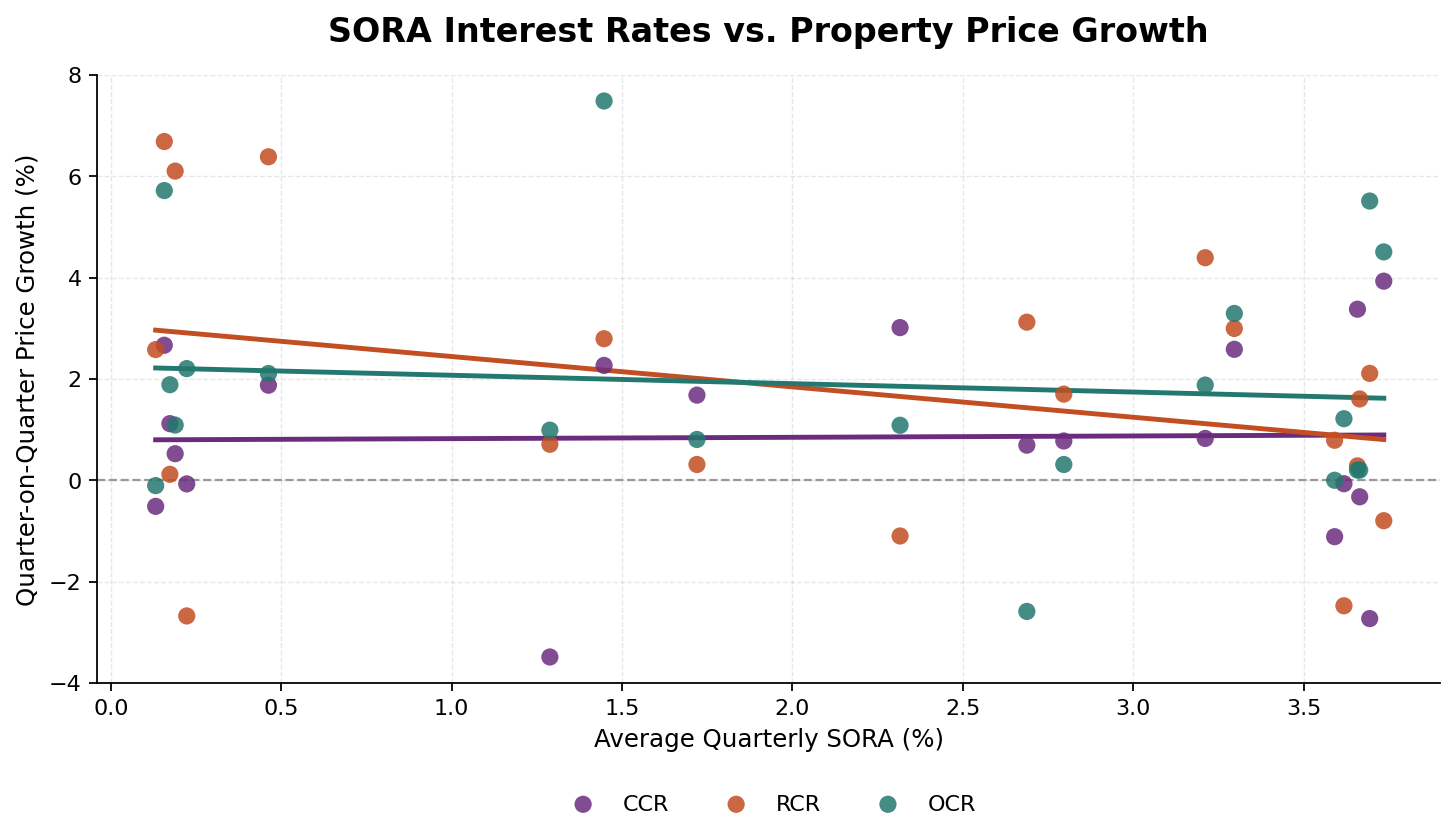

In [196]:
#4.4.3 Scatter plot with trendlines


fig, ax = plt.subplots(figsize=(9.2, 5.4), dpi=160)

for region in REGIONS:
    data = merged_df[
        merged_df["market_segment"] == region
    ]

    x = data["avg_sora"].to_numpy()
    y = data["qoq_growth"].to_numpy()

    # Quarterly observations
    ax.scatter(
        x, y,
        s=60,
        color=COLORS[region],
        alpha=0.85,
        edgecolors="none",
        label=region,
        zorder=3
    )

    # Linear regression trendline
    if len(x) >= 2 and np.unique(x).size >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 150)
        y_line = slope * x_line + intercept

        ax.plot(
            x_line, y_line,
            color=COLORS[region],
            linewidth=2.2,
            zorder=2
        )

# Horizontal zero-growth reference line
ax.axhline(
    0, color="#999999",
    linestyle="--", linewidth=1
)

ax.set_title(
    "SORA Interest Rates vs. Property Price Growth",
    fontsize=15, fontweight="bold", pad=15
)

ax.set_xlabel("Average Quarterly SORA (%)", fontsize=11)
ax.set_ylabel("Quarter-on-Quarter Price Growth (%)", fontsize=11)

ax.set_xlim(-0.04, 3.9)
ax.set_ylim(-4, 8)

ax.grid(
    True, linestyle="--",
    linewidth=0.6, alpha=0.3
)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend below the chart
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=False,
    fontsize=10
)

plt.tight_layout()
plt.savefig(
    "4_4_SORA_Scatter.png",
    dpi=300, bbox_inches="tight", facecolor="white"
)
plt.show()
